# Set Up


## Libraries

In [2]:
import os
import sys
import re

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    RegexTokenizer,
    StopWordsRemover,
    CountVectorizer
)
from pyspark.ml.clustering import LDA

## Path

In [9]:
# S3 locations
S3_BUCKET = "s3a://dsan6000-jg2292/ancient-battles"

CLEANED_DIR = f"{S3_BUCKET}/processed/cleaned_articles"

NLP_DIR = f"{S3_BUCKET}/processed/nlp"

LDA_DIR = f"{S3_BUCKET}/models/lda"

# Intermediate NLP outputs
TOKENIZED_DIR = f"{NLP_DIR}/standard_stopwords_removed"

TERM_FREQ_DIR = f"{NLP_DIR}/term_frequency"

FINAL_TOKENS_DIR = f"{NLP_DIR}/final_tokens"

# Document-term matrix and vocabulary model
DTM_DIR = f"{NLP_DIR}/document_term_matrix"

CV_MODEL_DIR = f"{NLP_DIR}/count_vectorizer_model"

# LDA outputs
LDA_MODEL_DIR = f"{LDA_DIR}/model"

TOPIC_DISTRIBUTIONS_DIR = f"{LDA_DIR}/article_topic_distributions"

# Initialize Spark

In [4]:
# Spark configuration
SPARK_APP_NAME = "Ancient Battles - LDA"

SPARK_MASTER = "spark://ip-172-31-46-25.ec2.internal:7077"

# Initialize Spark
spark = (
    SparkSession.builder
    .appName(SPARK_APP_NAME)
    .master(SPARK_MASTER)
    .config(
        "spark.jars.packages",
        "org.apache.hadoop:hadoop-aws:3.5.0"
    )
    .getOrCreate()
)

spark.conf.set(
    "spark.sql.execution.pythonUDF.arrow.enabled",
    "false"
)

# Display Spark configuration
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Application ID:", spark.sparkContext.applicationId)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

:: loading settings :: url = jar:file:/home/ubuntu/spark-4.3.0-bin-hadoop3/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-aws added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-66a74347-64a4-489d-a497-2b9eaa838230;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-aws;3.5.0 in central
	found software.amazon.awssdk#bundle;2.35.4 in central
	found software.amazon.s3.analyticsaccelerator#analyticsaccelerator-s3;1.3.1 in central
	found org.wildfly.openssl#wildfly-openssl;2.2.5.Final in central
:: resolution report :: resolve 446ms :: artifacts dl 27ms
	:: modules in use:
	org.apache.hadoop#hadoop-aws;3.5.0 from central in [default]
	org.wildfly.openssl#wildfly-openssl;2.2.5.Final from central in [default]
	software.amazon.awssdk#bundle;2.35.4 from central in [default]
	software.amazon.s3.an

Spark version: 4.3.0
Spark master: spark://ip-172-31-46-25.ec2.internal:7077
Application ID: app-20261115223852-0002
Default parallelism: 8


### Verify distributed execution

In [5]:
# Check available parallelism
print("Default parallelism:", spark.sparkContext.defaultParallelism)

# Test distributed execution
test_rdd = spark.sparkContext.parallelize(range(1, 101), 8)

print("Test sum:", test_rdd.sum())
print("Number of partitions:", test_rdd.getNumPartitions())

Default parallelism: 8


Test sum: 5050
Number of partitions: 8


# NLP Preparation

## Read Cleaned Articles

In [7]:
# Read cleaned articles from S3
nlp_articles_df = spark.read.parquet(CLEANED_DIR)

# Keep the primary corpus: crawl depth 0 and 1
nlp_articles_df = (
    nlp_articles_df
    .filter(F.col("crawl_depth") <= 1)
    .select(
        "page_id",
        "title",
        "crawl_depth",
        "cleaned_text"
    )
)

# Inspect the dataset
print("Article count:", nlp_articles_df.count())

print("\nSchema:")
nlp_articles_df.printSchema()

print("\nSample articles:")
nlp_articles_df.show(5, truncate=150)

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


Article count: 9015

Schema:
root
 |-- page_id: long (nullable = true)
 |-- title: string (nullable = true)
 |-- crawl_depth: integer (nullable = true)
 |-- cleaned_text: string (nullable = true)


Sample articles:


+--------+-------------------------+-----------+------------------------------------------------------------------------------------------------------------------------------------------------------+
| page_id|                    title|crawl_depth|                                                                                                                                          cleaned_text|
+--------+-------------------------+-----------+------------------------------------------------------------------------------------------------------------------------------------------------------+
|53903318|         Battle of Arbalo|          0|The Battle of Arbalo was fought between the Romans and Germanic peoples in 11 BC in a narrow pass called Arbalo somewhere west of the Weser and pro...|
| 3127340|Battle of the Lupia River|          0|The Battle of the Lupia River was fought in 11 BC between a Roman force led by Nero Claudius Drusus and the Sicambri. The Lupia River, now Lippe, f...|


## Inspect Article Text

In [8]:
# Calculate article text length
nlp_articles_df = nlp_articles_df.withColumn(
    "text_length",
    F.length(F.col("cleaned_text"))
)

# Summarize article text lengths and missing values
nlp_articles_df.agg(
    F.count("*").alias("total_articles"),
    F.sum(
        F.when(F.col("cleaned_text").isNull(), 1).otherwise(0)
    ).alias("null_articles"),
    F.sum(
        F.when(F.trim(F.col("cleaned_text")) == "", 1).otherwise(0)
    ).alias("empty_articles"),
    F.min("text_length").alias("minimum_characters"),
    F.round(F.avg("text_length"), 2).alias("average_characters"),
    F.expr("percentile_approx(text_length, 0.5)").alias("median_characters"),
    F.max("text_length").alias("maximum_characters")
).show(truncate=False)

+--------------+-------------+--------------+------------------+------------------+-----------------+------------------+
|total_articles|null_articles|empty_articles|minimum_characters|average_characters|median_characters|maximum_characters|
+--------------+-------------+--------------+------------------+------------------+-----------------+------------------+
|9015          |0            |0             |43                |13065.98          |6062             |228574            |
+--------------+-------------+--------------+------------------+------------------+-----------------+------------------+



## Tokenization and standard stopword removal

In [10]:
# Initialize tokenizer
tokenizer = RegexTokenizer(
    inputCol="cleaned_text",
    outputCol="tokens",
    pattern="\\W+",
    minTokenLength=3,
    toLowercase=True
)

# Tokenize articles
tokenized_df = tokenizer.transform(nlp_articles_df)

# Remove standard English stopwords
stopword_remover = StopWordsRemover(
    inputCol="tokens",
    outputCol="filtered_tokens"
)

standard_tokens_df = stopword_remover.transform(tokenized_df)

# Keep only fields needed for subsequent NLP processing
standard_tokens_df = standard_tokens_df.select(
    "page_id",
    "title",
    "crawl_depth",
    "filtered_tokens"
)

### Saved

In [11]:
# Save tokenized articles with standard stopwords removed
standard_tokens_df.write \
    .mode("overwrite") \
    .parquet(TOKENIZED_DIR)

print("Saved standard-tokenized articles to:", TOKENIZED_DIR)

Saved standard-tokenized articles to: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/standard_stopwords_removed


## Inspect frequent terms

In [12]:
# Read saved tokenized data
standard_tokens_df = spark.read.parquet(TOKENIZED_DIR)

# Calculate term frequency and approximate document frequency
term_frequency_df = (
    standard_tokens_df
    .select(
        "page_id",
        F.explode("filtered_tokens").alias("term")
    )
    .groupBy("term")
    .agg(
        F.count("*").alias("total_occurrences"),
        F.approx_count_distinct("page_id").alias("approx_document_frequency")
    )
    .orderBy(F.desc("total_occurrences"))
)

# Save term frequency results
term_frequency_df.write \
    .mode("overwrite") \
    .parquet(TERM_FREQ_DIR)

# Display the 60 most frequent terms
spark.read.parquet(TERM_FREQ_DIR) \
    .show(60, truncate=False)

26/11/15 22:53:39 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------------+-----------------+-------------------------+
|term          |total_occurrences|approx_document_frequency|
+--------------+-----------------+-------------------------+
|abhinavagupta |1                |1                        |
|jonang        |1                |1                        |
|syburg        |1                |1                        |
|pseudorapidity|1                |1                        |
|fuzier        |1                |1                        |
|sarisai       |1                |1                        |
|56d           |1                |1                        |
|2069          |1                |1                        |
|holotype      |1                |1                        |
|kadman        |1                |1                        |
|shakhsheer    |1                |1                        |
|pro4          |1                |1                        |
|alcibiade     |1                |1                        |
|vassilias     |1       

In [15]:
# Domain-specific stopwords identified after inspecting term frequencies
domain_stopwords = ["reference"

]

# Initialize domain-specific stopword remover
domain_stopword_remover = StopWordsRemover(
    inputCol="filtered_tokens",
    outputCol="final_tokens",
    stopWords=domain_stopwords
)

# Remove domain-specific terms
final_tokens_df = domain_stopword_remover.transform(
    standard_tokens_df
)

# Keep required fields
final_tokens_df = final_tokens_df.select(
    "page_id",
    "title",
    "crawl_depth",
    "final_tokens"
)

# Save final preprocessed articles
final_tokens_df.write \
    .mode("overwrite") \
    .parquet(FINAL_TOKENS_DIR)

print("Saved final preprocessed articles to:", FINAL_TOKENS_DIR)

Saved final preprocessed articles to: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/final_tokens


## Build vocabulary

In [16]:
# Read final preprocessed articles
final_tokens_df = spark.read.parquet(FINAL_TOKENS_DIR)

# Configure CountVectorizer
count_vectorizer = CountVectorizer(
    inputCol="final_tokens",
    outputCol="features",
    vocabSize=20000,
    minDF=3.0,
    maxDF=0.80
)

# Fit vocabulary
cv_model = count_vectorizer.fit(final_tokens_df)

# Save fitted vocabulary model
cv_model.write().overwrite().save(CV_MODEL_DIR)

# Inspect vocabulary
vocabulary = cv_model.vocabulary

print("Vocabulary size:", len(vocabulary))
print("First 50 terms:", vocabulary[:50])

26/11/15 22:56:33 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.


Vocabulary size: 20000
First 50 terms: ['roman', 'century', 'city', 'one', 'first', 'war', 'two', 'battle', 'king', 'army', 'later', 'time', 'many', 'known', 'empire', '000', 'new', 'used', 'early', 'emperor', 'people', 'however', 'greek', 'period', 'part', 'name', 'became', 'ancient', 'rome', 'modern', 'may', 'military', 'north', 'three', 'history', 'years', 'made', 'around', 'river', 'well', 'world', 'including', 'south', 'region', 'state', 'according', 'area', 'forces', 'east', 'year']


## Create document-term matrix

In [17]:
# Transform articles into document-term vectors
document_term_df = cv_model.transform(final_tokens_df)

# Keep article identifiers and feature vectors
document_term_df = document_term_df.select(
    "page_id",
    "title",
    "crawl_depth",
    "features"
)

# Save document-term matrix
document_term_df.write \
    .mode("overwrite") \
    .parquet(DTM_DIR)

print("Saved document-term matrix to:", DTM_DIR)

Saved document-term matrix to: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/document_term_matrix


# Train LDA

In [18]:
# LDA configuration
NUM_TOPICS = 15
MAX_ITERATIONS = 20
RANDOM_SEED = 6000

lda = LDA(
    k=NUM_TOPICS,
    maxIter=MAX_ITERATIONS,
    optimizer="online",
    featuresCol="features",
    topicDistributionCol="topicDistribution",
    seed=RANDOM_SEED
)

print("Number of topics:", NUM_TOPICS)
print("Maximum iterations:", MAX_ITERATIONS)
print("Optimizer: online")
print("Random seed:", RANDOM_SEED)

Number of topics: 15
Maximum iterations: 20
Optimizer: online
Random seed: 6000


## Load saved document-term matrix

In [19]:

document_term_df = spark.read.parquet(DTM_DIR)

# Train LDA model
lda_model = lda.fit(document_term_df)

# Save trained model
lda_model.write().overwrite().save(LDA_MODEL_DIR)

print("LDA model saved to:", LDA_MODEL_DIR)

26/11/15 23:06:29 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
26/11/15 23:06:31 WARN TaskSetManager: Stage 117 contains a task of very large size (2403 KiB). The maximum recommended task size is 1000 KiB.


LDA model saved to: s3a://dsan6000-jg2292/ancient-battles/models/lda/model


## Inspect topics

In [20]:
# Extract the 15 highest-weight terms for each topic
topic_terms_df = lda_model.describeTopics(
    maxTermsPerTopic=15
)

# Collect only the small topic summary
topic_rows = topic_terms_df.collect()

# Display topic terms using the fitted vocabulary
for row in topic_rows:
    print(f"\nTopic {row.topic}")

    for term_index, weight in zip(
        row.termIndices,
        row.termWeights
    ):
        print(
            f"  {vocabulary[term_index]}: {weight:.4f}"
        )


Topic 0
  sasanian: 0.0076
  persian: 0.0073
  huns: 0.0068
  iranian: 0.0058
  varaha: 0.0044
  empire: 0.0041
  king: 0.0041
  iran: 0.0040
  india: 0.0035
  century: 0.0034
  vishnu: 0.0032
  sri: 0.0030
  buddhist: 0.0030
  turkic: 0.0029
  one: 0.0029

Topic 1
  one: 0.0044
  century: 0.0043
  roman: 0.0039
  used: 0.0037
  first: 0.0033
  may: 0.0033
  two: 0.0029
  war: 0.0029
  many: 0.0027
  time: 0.0026
  known: 0.0025
  name: 0.0022
  irish: 0.0022
  military: 0.0022
  king: 0.0022

Topic 2
  roman: 0.0148
  battle: 0.0070
  army: 0.0070
  war: 0.0067
  rome: 0.0064
  caesar: 0.0048
  romans: 0.0046
  city: 0.0042
  king: 0.0035
  first: 0.0034
  two: 0.0033
  one: 0.0032
  empire: 0.0031
  emperor: 0.0031
  000: 0.0029

Topic 3
  city: 0.0086
  century: 0.0062
  first: 0.0041
  one: 0.0038
  war: 0.0033
  new: 0.0030
  french: 0.0029
  world: 0.0029
  two: 0.0028
  university: 0.0028
  history: 0.0027
  roman: 0.0025
  france: 0.0025
  spanish: 0.0024
  part: 0.0023

Topic

# Extract article-topic distributions

In [21]:
# Generate topic distributions for each article
article_topics_df = lda_model.transform(document_term_df)

# Keep article identifiers and topic distributions
article_topics_df = article_topics_df.select(
    "page_id",
    "title",
    "crawl_depth",
    "topicDistribution"
)

# Save article-topic distributions
article_topics_df.write \
    .mode("overwrite") \
    .parquet(TOPIC_DISTRIBUTIONS_DIR)

print(
    "Saved article-topic distributions to:",
    TOPIC_DISTRIBUTIONS_DIR
)

26/11/15 23:07:21 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB


Saved article-topic distributions to: s3a://dsan6000-jg2292/ancient-battles/models/lda/article_topic_distributions


# Verify saved outputs

In [22]:
# Verify preprocessing outputs
print("Standard tokens:", TOKENIZED_DIR)
print("Term frequencies:", TERM_FREQ_DIR)
print("Final tokens:", FINAL_TOKENS_DIR)
print("Document-term matrix:", DTM_DIR)
print("Vocabulary model:", CV_MODEL_DIR)

# Verify LDA outputs
print("LDA model:", LDA_MODEL_DIR)
print("Article-topic distributions:", TOPIC_DISTRIBUTIONS_DIR)

# Read saved article-topic distributions
saved_topics_df = spark.read.parquet(TOPIC_DISTRIBUTIONS_DIR)

print("\nSaved topic distribution schema:")
saved_topics_df.printSchema()

print("\nSample article-topic distributions:")
saved_topics_df.show(5, truncate=False)

Standard tokens: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/standard_stopwords_removed
Term frequencies: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/term_frequency
Final tokens: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/final_tokens
Document-term matrix: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/document_term_matrix
Vocabulary model: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/count_vectorizer_model
LDA model: s3a://dsan6000-jg2292/ancient-battles/models/lda/model
Article-topic distributions: s3a://dsan6000-jg2292/ancient-battles/models/lda/article_topic_distributions

Saved topic distribution schema:
root
 |-- page_id: long (nullable = true)
 |-- title: string (nullable = true)
 |-- crawl_depth: integer (nullable = true)
 |-- topicDistribution: vector (nullable = true)


Sample article-topic distributions:
+--------+---------------------------------------------------------------+-----------+--------------------------------------------------

# Reviewing LDA results

In [27]:
import math
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pyspark.ml.functions import vector_to_array

## Evaluate Topic Distributions

In [24]:
# Read previously saved article-topic distributions
article_topics_df = spark.read.parquet(TOPIC_DISTRIBUTIONS_DIR)

# Convert topic vectors to arrays for distributed calculations
distribution_metrics_df = (
    article_topics_df
    .withColumn(
        "topic_probs",
        vector_to_array(F.col("topicDistribution"))
    )
    .withColumn(
        "max_topic_probability",
        F.array_max("topic_probs")
    )
    .withColumn(
        "topics_at_5pct",
        F.expr("""
            aggregate(
                topic_probs,
                0,
                (acc, p) -> acc + IF(p >= 0.05, 1, 0)
            )
        """)
    )
    .withColumn(
        "topic_entropy",
        F.expr("""
            aggregate(
                topic_probs,
                0.0D,
                (acc, p) ->
                    acc - CASE
                        WHEN p > 0 THEN p * log(p)
                        ELSE 0.0D
                    END
            )
        """)
    )
    .withColumn(
        "normalized_entropy",
        F.col("topic_entropy") / F.lit(math.log(NUM_TOPICS))
    )
)

# Retain article-level diagnostic measures
distribution_metrics_df = distribution_metrics_df.select(
    "page_id",
    "title",
    "crawl_depth",
    "max_topic_probability",
    "topics_at_5pct",
    "topic_entropy",
    "normalized_entropy"
)

# Save article-level diagnostics to S3
DIAGNOSTICS_DIR = f"{NLP_DIR}/topic_distribution_diagnostics"

distribution_metrics_df.write.mode("overwrite").parquet(
    f"{DIAGNOSTICS_DIR}/article_metrics"
)

print("Article-level diagnostic metrics saved.")

Article-level diagnostic metrics saved.


## Calculate summary statistics by crawl depth

In [25]:
depth_summary_df = (
    distribution_metrics_df
    .groupBy("crawl_depth")
    .agg(
        F.count("*").alias("article_count"),
        F.avg("max_topic_probability").alias("avg_max_topic_probability"),
        F.avg("topics_at_5pct").alias("avg_topics_at_5pct"),
        F.avg("topic_entropy").alias("avg_topic_entropy"),
        F.avg("normalized_entropy").alias("avg_normalized_entropy")
    )
    .orderBy("crawl_depth")
)

depth_summary_df.write.mode("overwrite").parquet(
    f"{DIAGNOSTICS_DIR}/depth_summary"
)

depth_summary_df.show(truncate=False)

+-----------+-------------+-------------------------+------------------+------------------+----------------------+
|crawl_depth|article_count|avg_max_topic_probability|avg_topics_at_5pct|avg_topic_entropy |avg_normalized_entropy|
+-----------+-------------+-------------------------+------------------+------------------+----------------------+
|0          |432          |0.9004185319237819       |1.4444444444444444|0.259561512901526 |0.09584811714195002   |
|1          |8583         |0.7301220146237759       |2.250728183618781 |0.6256849118048687|0.23104627512082565   |
+-----------+-------------+-------------------------+------------------+------------------+----------------------+



### Visualization

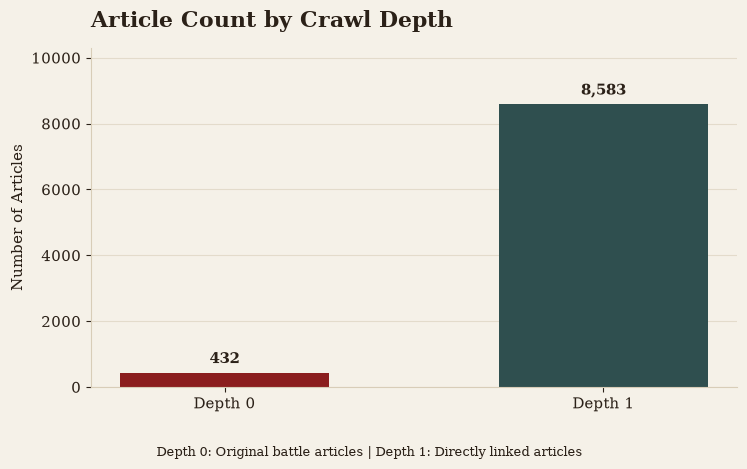

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/article_count_by_crawl_depth.png


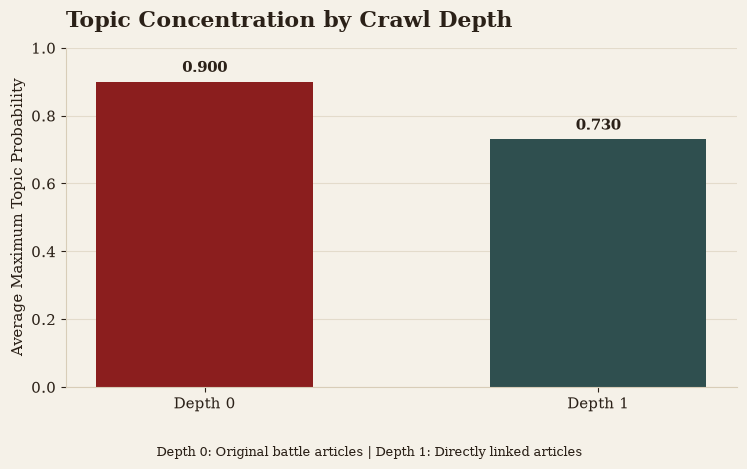

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_concentration_by_crawl_depth.png


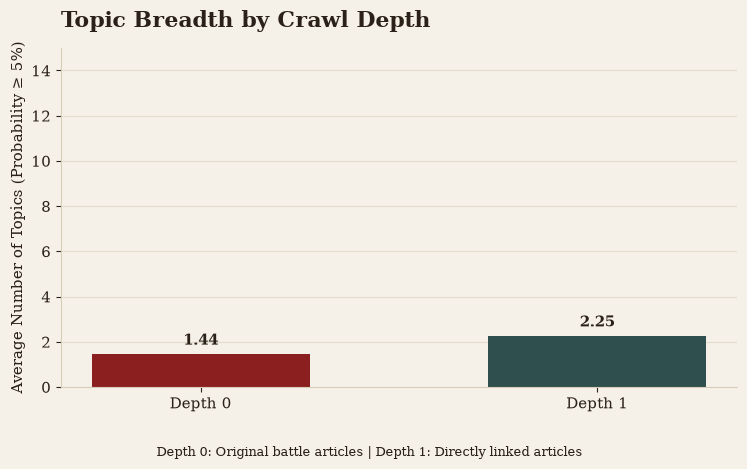

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_breadth_by_crawl_depth.png


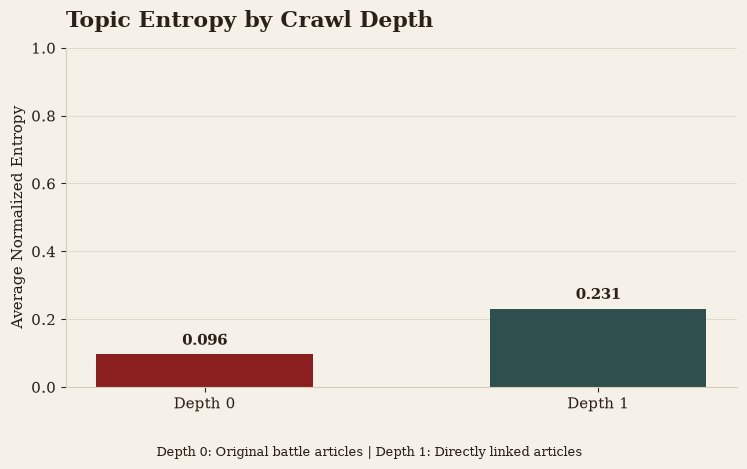

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_entropy_by_crawl_depth.png


In [29]:
# Historical visualization palette
HISTORICAL_PALETTE = {
    "primary": "#8B1E1E",
    "secondary": "#C9A227",
    "accent": "#2F4F4F",
    "background": "#F5F1E8",
    "text": "#2B2118",
    "grid": "#D8CDB8"
}

# Retrieve the generated Spark summary results
depth_summary_rows = (
    depth_summary_df
    .orderBy("crawl_depth")
    .collect()
)

# Extract values directly from the Spark results
depth_labels = [
    f"Depth {row['crawl_depth']}"
    for row in depth_summary_rows
]

article_counts = [
    row["article_count"]
    for row in depth_summary_rows
]

max_topic_probability = [
    row["avg_max_topic_probability"]
    for row in depth_summary_rows
]

topics_at_5pct = [
    row["avg_topics_at_5pct"]
    for row in depth_summary_rows
]

normalized_entropy = [
    row["avg_normalized_entropy"]
    for row in depth_summary_rows
]

depth_colors = [
    HISTORICAL_PALETTE["primary"],
    HISTORICAL_PALETTE["accent"]
]

# Configure visualization theme
plt.rcParams.update({
    "figure.facecolor": HISTORICAL_PALETTE["background"],
    "axes.facecolor": HISTORICAL_PALETTE["background"],
    "axes.edgecolor": HISTORICAL_PALETTE["grid"],
    "axes.labelcolor": HISTORICAL_PALETTE["text"],
    "text.color": HISTORICAL_PALETTE["text"],
    "xtick.color": HISTORICAL_PALETTE["text"],
    "ytick.color": HISTORICAL_PALETTE["text"],
    "grid.color": HISTORICAL_PALETTE["grid"],
    "font.family": "serif",
    "font.size": 11
})

# Create images folder in project directory
IMAGE_DIR = Path.cwd() / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)


# Reusable function for creating and saving individual figures
def create_depth_chart(
    values,
    title,
    ylabel,
    filename,
    y_limits=None,
    number_format="{:.2f}"
):

    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(
        depth_labels,
        values,
        color=depth_colors,
        width=0.55
    )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        loc="left",
        pad=15
    )

    ax.set_ylabel(ylabel, fontsize=11)

    if y_limits:
        ax.set_ylim(y_limits)
    else:
        ax.set_ylim(0, max(values) * 1.2)

    ax.grid(axis="y", alpha=0.6)
    ax.set_axisbelow(True)

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Add values above bars
    for bar, value in zip(bars, values):

        ax.annotate(
            number_format.format(value),
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

    # Add explanatory caption
    fig.text(
        0.5,
        0.025,
        "Depth 0: Original battle articles | Depth 1: Directly linked articles",
        ha="center",
        fontsize=9,
        color=HISTORICAL_PALETTE["text"]
    )

    plt.tight_layout(rect=[0.03, 0.08, 0.98, 0.95])

    # Save figure
    figure_path = IMAGE_DIR / filename

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

    print("Figure saved to:", figure_path.resolve())


# 1. Article Count
create_depth_chart(
    values=article_counts,
    title="Article Count by Crawl Depth",
    ylabel="Number of Articles",
    filename="article_count_by_crawl_depth.png",
    number_format="{:,.0f}"
)


# 2. Topic Concentration
create_depth_chart(
    values=max_topic_probability,
    title="Topic Concentration by Crawl Depth",
    ylabel="Average Maximum Topic Probability",
    filename="topic_concentration_by_crawl_depth.png",
    y_limits=(0, 1),
    number_format="{:.3f}"
)


# 3. Topic Breadth
create_depth_chart(
    values=topics_at_5pct,
    title="Topic Breadth by Crawl Depth",
    ylabel="Average Number of Topics (Probability ≥ 5%)",
    filename="topic_breadth_by_crawl_depth.png",
    y_limits=(0, 15),
    number_format="{:.2f}"
)


# 4. Topic Entropy
create_depth_chart(
    values=normalized_entropy,
    title="Topic Entropy by Crawl Depth",
    ylabel="Average Normalized Entropy",
    filename="topic_entropy_by_crawl_depth.png",
    y_limits=(0, 1),
    number_format="{:.3f}"
)

## Topic Prevalence

In [30]:
from pyspark.ml.functions import vector_to_array

# Read the saved article-topic distributions
article_topics_df = spark.read.parquet(TOPIC_DISTRIBUTIONS_DIR)

# Convert each article's topic probability vector into individual topic rows
topic_probabilities_df = (
    article_topics_df
    .select(
        "page_id",
        "crawl_depth",
        F.posexplode(
            vector_to_array("topicDistribution")
        ).alias("topic_index", "topic_probability")
    )
)

# Calculate prevalence and coverage for each topic and crawl depth
topic_prevalence_df = (
    topic_probabilities_df
    .groupBy("crawl_depth", "topic_index")
    .agg(
        F.avg("topic_probability").alias("avg_topic_probability"),
        F.avg(
            F.when(F.col("topic_probability") >= 0.05, 1.0)
             .otherwise(0.0)
        ).alias("article_coverage")
    )
    .withColumn(
        "topic_number",
        F.col("topic_index") + 1
    )
    .withColumn(
        "article_coverage_pct",
        F.col("article_coverage") * 100
    )
    .orderBy("crawl_depth", "topic_index")
)

# Save diagnostic results
TOPIC_PREVALENCE_DIR = f"{DIAGNOSTICS_DIR}/topic_prevalence_by_depth"

topic_prevalence_df.write.mode("overwrite").parquet(
    TOPIC_PREVALENCE_DIR
)

# Display results
topic_prevalence_df.select(
    "crawl_depth",
    "topic_number",
    "avg_topic_probability",
    "article_coverage_pct"
).show(30, truncate=False)

+-----------+------------+---------------------+--------------------+
|crawl_depth|topic_number|avg_topic_probability|article_coverage_pct|
+-----------+------------+---------------------+--------------------+
|0          |1           |0.013779466801991377 |5.787037037037037   |
|0          |2           |0.033510326826339164 |10.416666666666668  |
|0          |3           |0.7710005035165735   |88.88888888888889   |
|0          |4           |0.0015103631419178956|0.6944444444444444  |
|0          |5           |0.02148052672877439  |6.25                |
|0          |6           |0.004295689767659671 |2.083333333333333   |
|0          |7           |4.994060828081929E-4 |0.23148148148148145 |
|0          |8           |0.00529629995844494  |2.7777777777777777  |
|0          |9           |3.384126798851097E-4 |0.0                 |
|0          |10          |0.00383570843587412  |1.1574074074074074  |
|0          |11          |0.004899453300402327 |2.083333333333333   |
|0          |12     

### Visualization

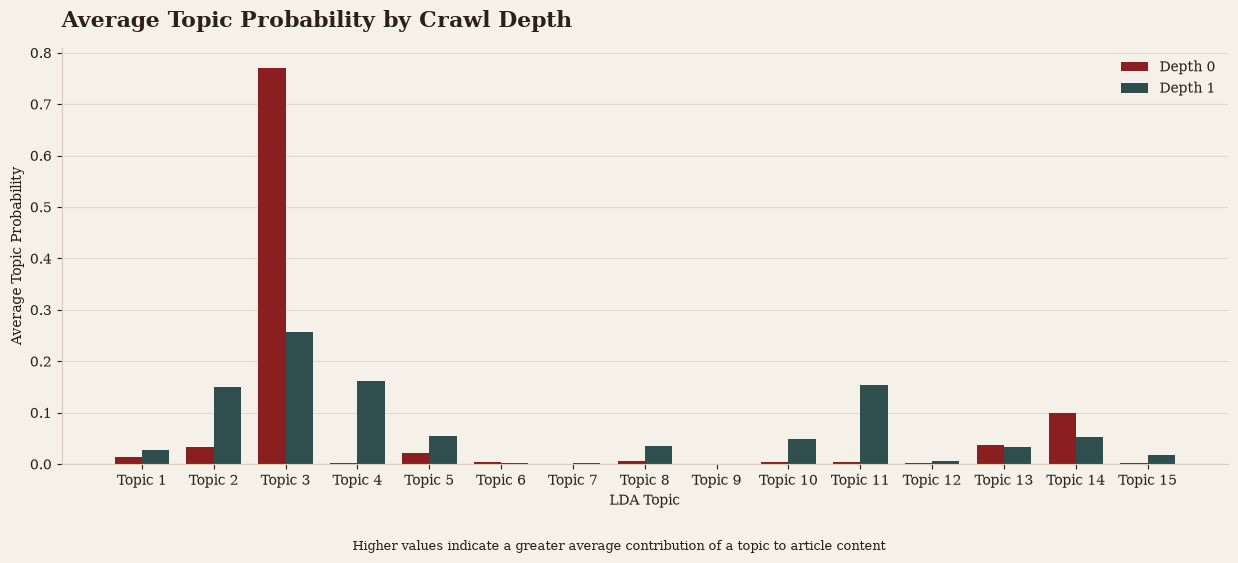

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/average_topic_probability_by_depth.png


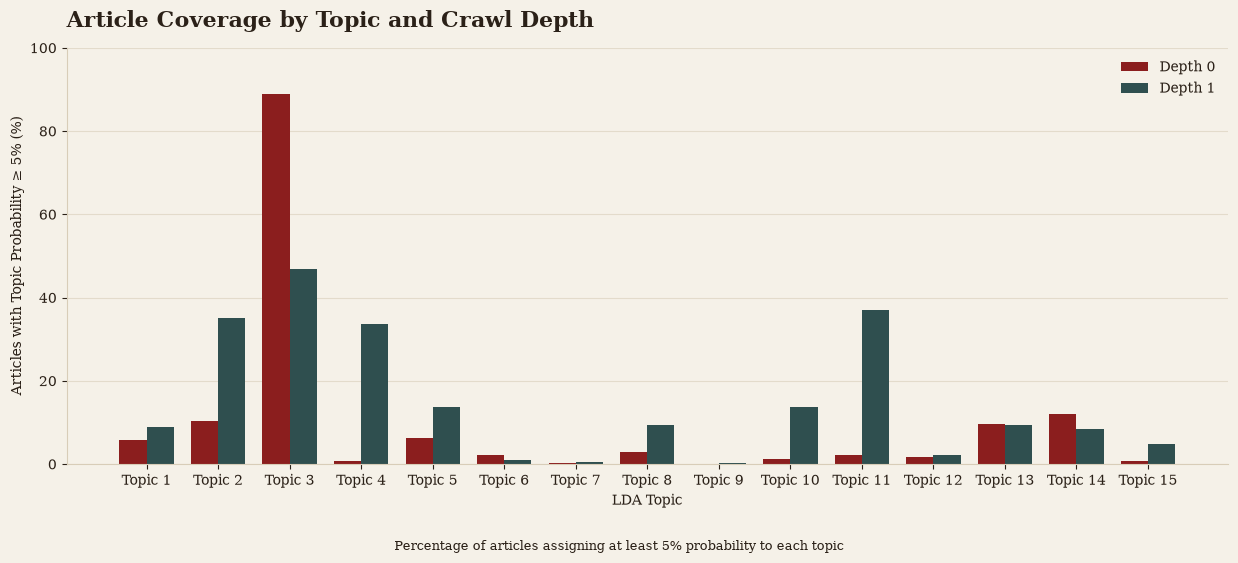

Figure saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_article_coverage_by_depth.png


In [31]:
# Historical visualization palette
HISTORICAL_PALETTE = {
    "primary": "#8B1E1E",
    "secondary": "#C9A227",
    "accent": "#2F4F4F",
    "background": "#F5F1E8",
    "text": "#2B2118",
    "grid": "#D8CDB8"
}

# Configure visualization theme
plt.rcParams.update({
    "figure.facecolor": HISTORICAL_PALETTE["background"],
    "axes.facecolor": HISTORICAL_PALETTE["background"],
    "axes.edgecolor": HISTORICAL_PALETTE["grid"],
    "axes.labelcolor": HISTORICAL_PALETTE["text"],
    "text.color": HISTORICAL_PALETTE["text"],
    "xtick.color": HISTORICAL_PALETTE["text"],
    "ytick.color": HISTORICAL_PALETTE["text"],
    "grid.color": HISTORICAL_PALETTE["grid"],
    "font.family": "serif",
    "font.size": 10
})

# Collect only the small aggregated diagnostic output
prevalence_rows = (
    topic_prevalence_df
    .select(
        "crawl_depth",
        "topic_number",
        "avg_topic_probability",
        "article_coverage_pct"
    )
    .orderBy("topic_number", "crawl_depth")
    .collect()
)

# Create image directory
IMAGE_DIR = Path.cwd() / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Extract topic labels and values
topic_numbers = sorted({
    row["topic_number"] for row in prevalence_rows
})

topic_labels = [f"Topic {n}" for n in topic_numbers]

depth_0 = {
    row["topic_number"]: row
    for row in prevalence_rows
    if row["crawl_depth"] == 0
}

depth_1 = {
    row["topic_number"]: row
    for row in prevalence_rows
    if row["crawl_depth"] == 1
}

# Prepare grouped values
avg_probability_0 = [
    depth_0[n]["avg_topic_probability"] for n in topic_numbers
]

avg_probability_1 = [
    depth_1[n]["avg_topic_probability"] for n in topic_numbers
]

coverage_0 = [
    depth_0[n]["article_coverage_pct"] for n in topic_numbers
]

coverage_1 = [
    depth_1[n]["article_coverage_pct"] for n in topic_numbers
]

x = np.arange(len(topic_numbers))
width = 0.38

depth_colors = [
    HISTORICAL_PALETTE["primary"],
    HISTORICAL_PALETTE["accent"]
]


# 1. Average Topic Probability
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    x - width / 2,
    avg_probability_0,
    width,
    label="Depth 0",
    color=depth_colors[0]
)

ax.bar(
    x + width / 2,
    avg_probability_1,
    width,
    label="Depth 1",
    color=depth_colors[1]
)

ax.set_title(
    "Average Topic Probability by Crawl Depth",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_ylabel("Average Topic Probability")
ax.set_xlabel("LDA Topic")
ax.set_xticks(x)
ax.set_xticklabels(topic_labels)

ax.grid(axis="y", alpha=0.6)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

fig.text(
    0.5,
    0.025,
    "Higher values indicate a greater average contribution of a topic to article content",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.95])

figure_path = IMAGE_DIR / "average_topic_probability_by_depth.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

print("Figure saved to:", figure_path.resolve())


# 2. Article Coverage by Topic
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    x - width / 2,
    coverage_0,
    width,
    label="Depth 0",
    color=depth_colors[0]
)

ax.bar(
    x + width / 2,
    coverage_1,
    width,
    label="Depth 1",
    color=depth_colors[1]
)

ax.set_title(
    "Article Coverage by Topic and Crawl Depth",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_ylabel("Articles with Topic Probability ≥ 5% (%)")
ax.set_xlabel("LDA Topic")
ax.set_xticks(x)
ax.set_xticklabels(topic_labels)
ax.set_ylim(0, 100)

ax.grid(axis="y", alpha=0.6)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

fig.text(
    0.5,
    0.025,
    "Percentage of articles assigning at least 5% probability to each topic",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.95])

figure_path = IMAGE_DIR / "topic_article_coverage_by_depth.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

print("Figure saved to:", figure_path.resolve())

## Top Words Per Topic

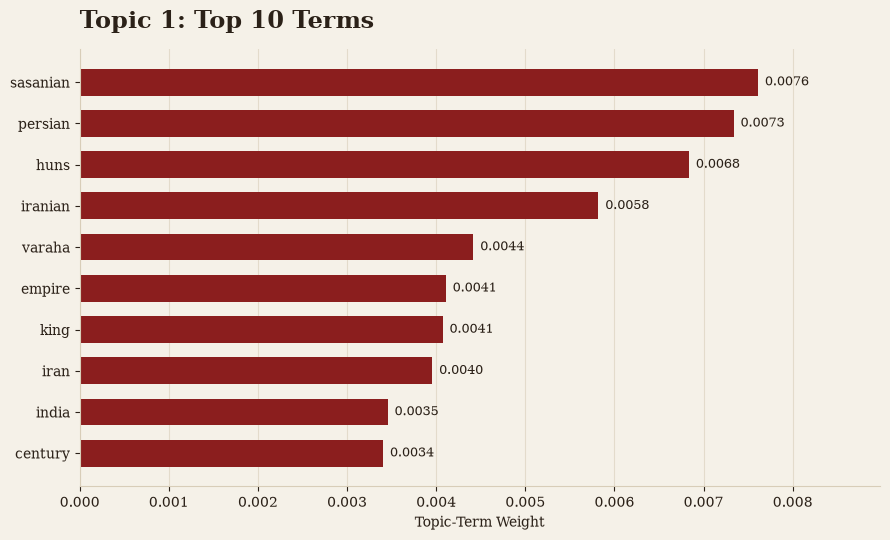

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_01_top_words.png


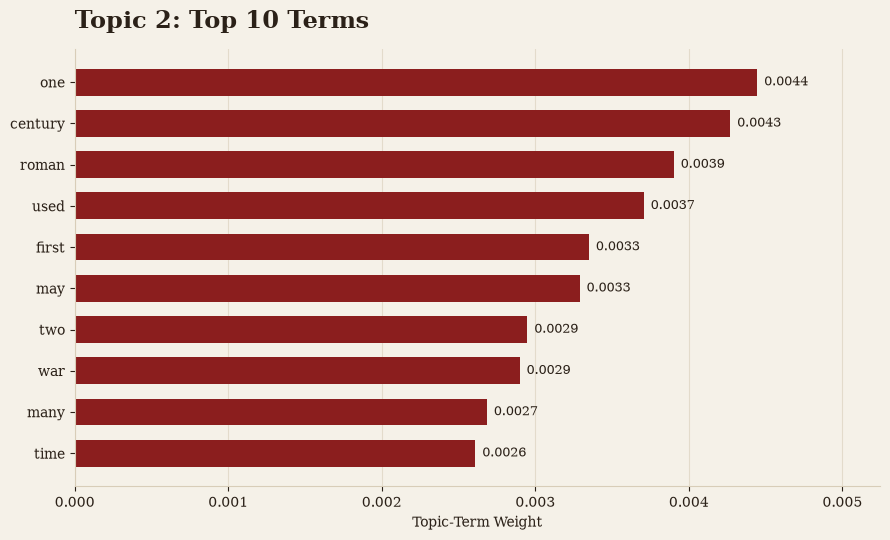

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_02_top_words.png


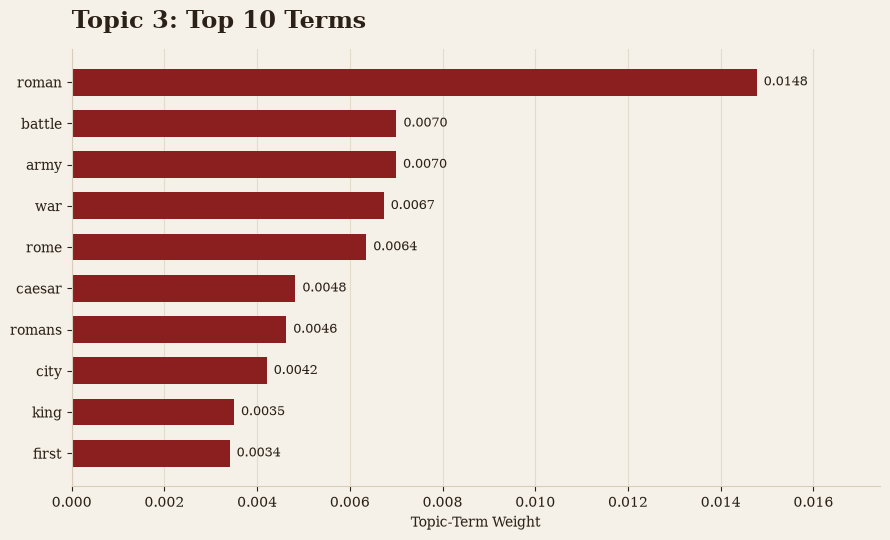

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_03_top_words.png


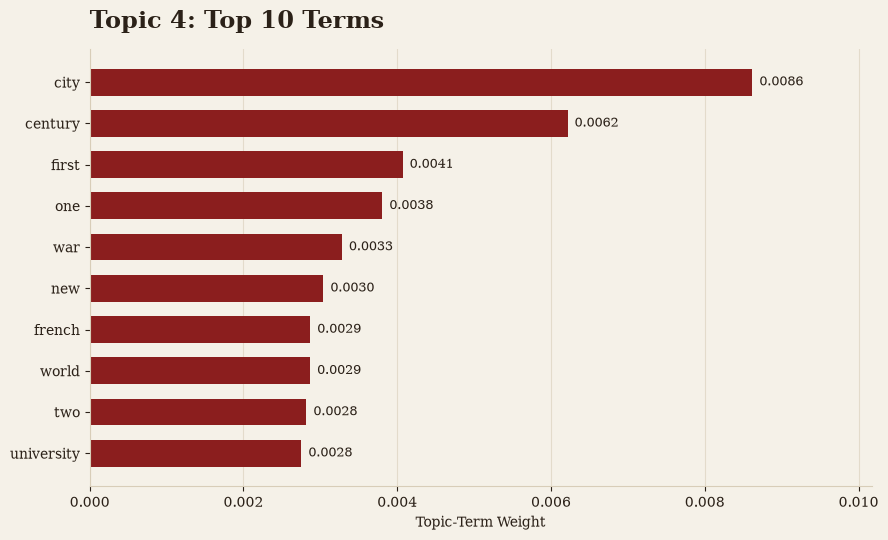

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_04_top_words.png


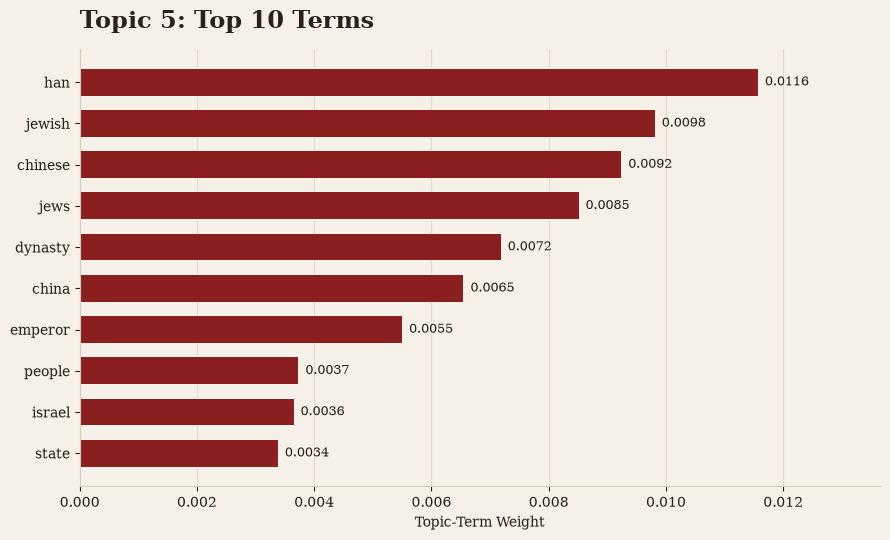

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_05_top_words.png


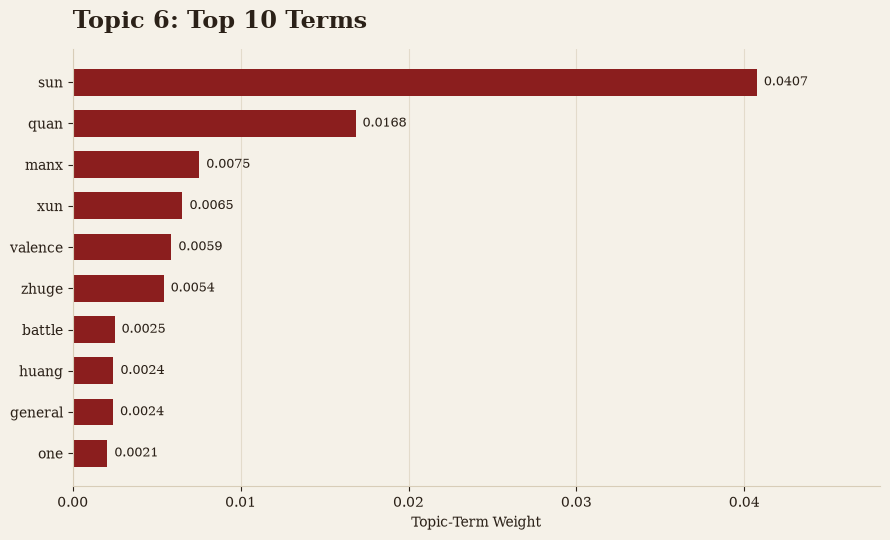

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_06_top_words.png


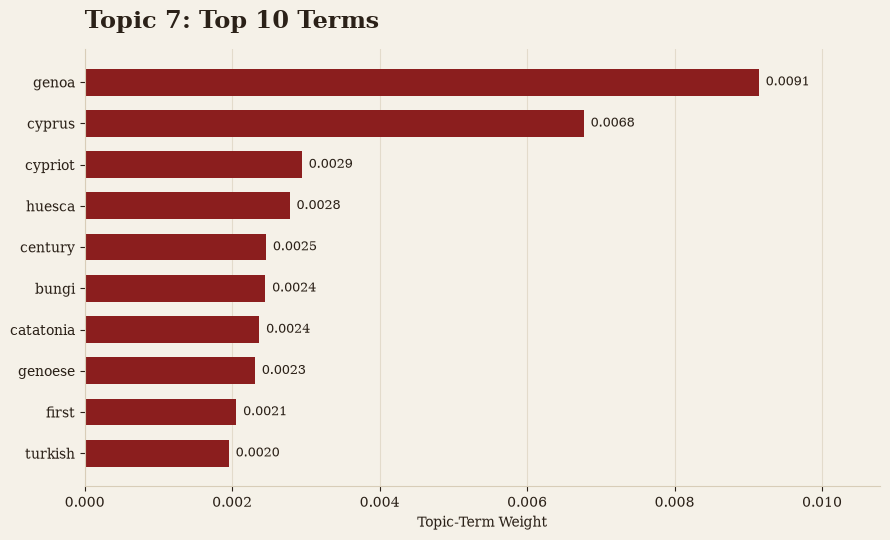

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_07_top_words.png


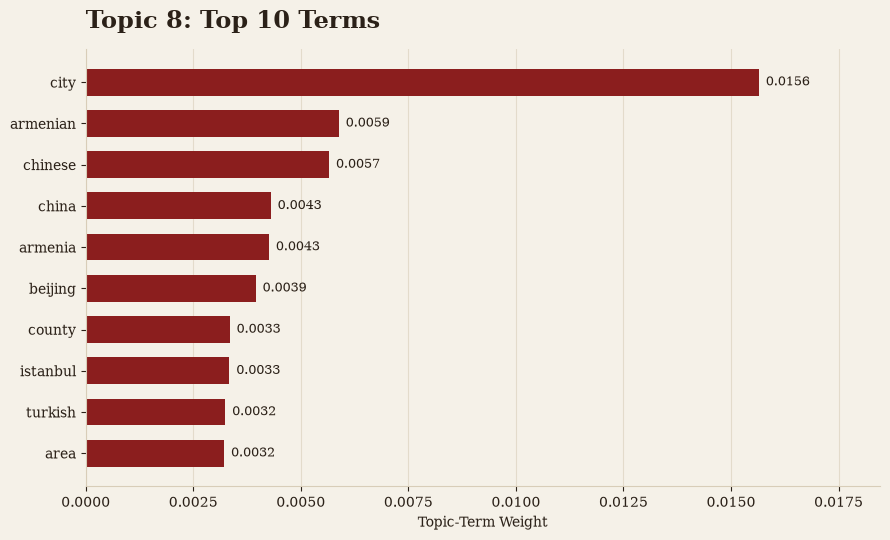

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_08_top_words.png


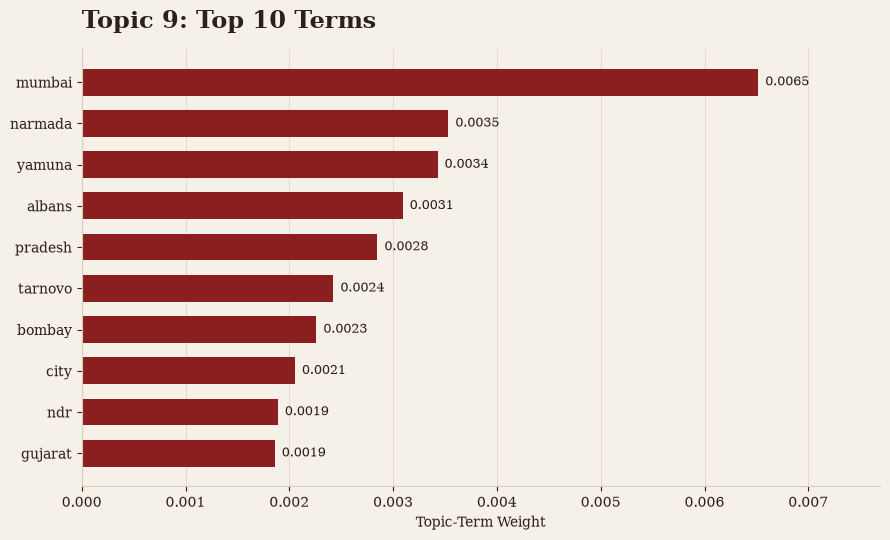

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_09_top_words.png


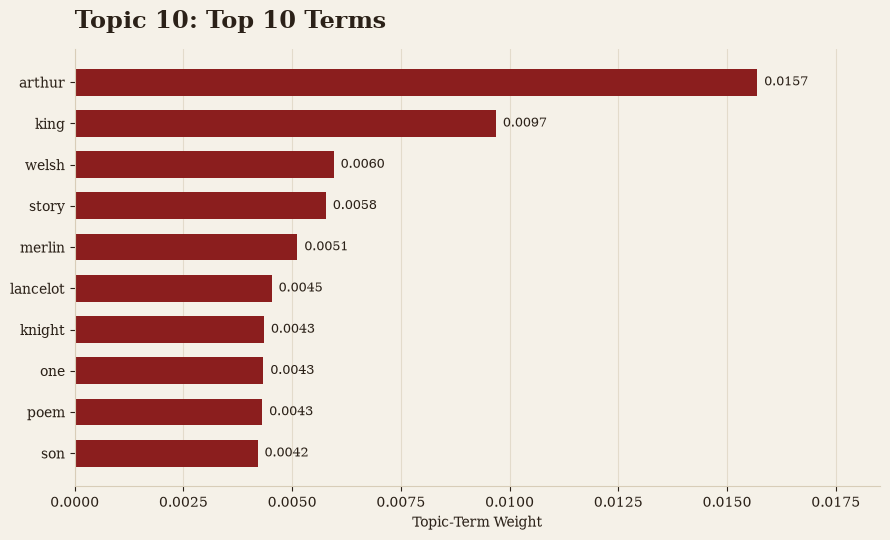

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_10_top_words.png


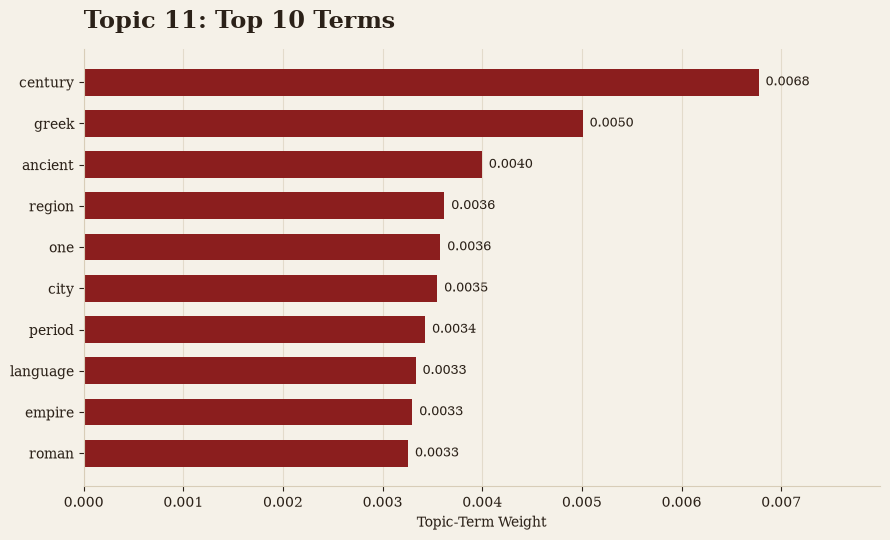

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_11_top_words.png


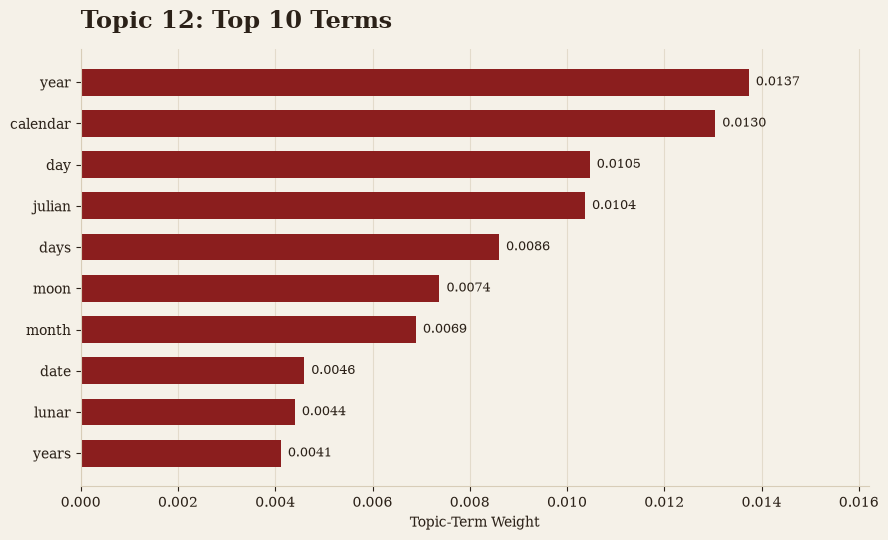

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_12_top_words.png


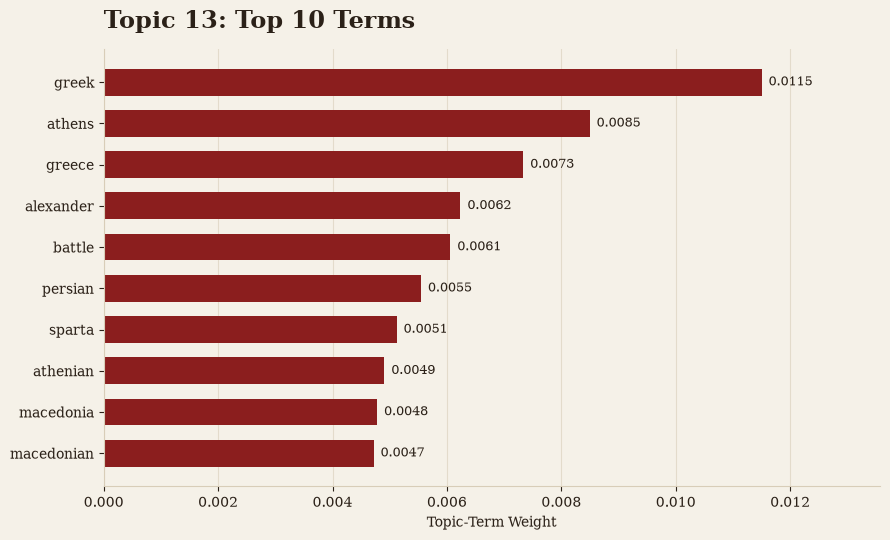

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_13_top_words.png


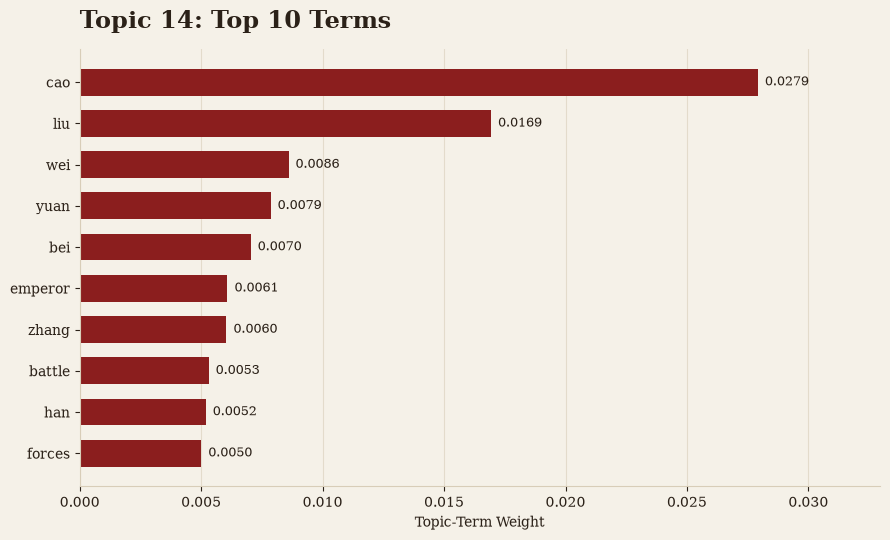

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_14_top_words.png


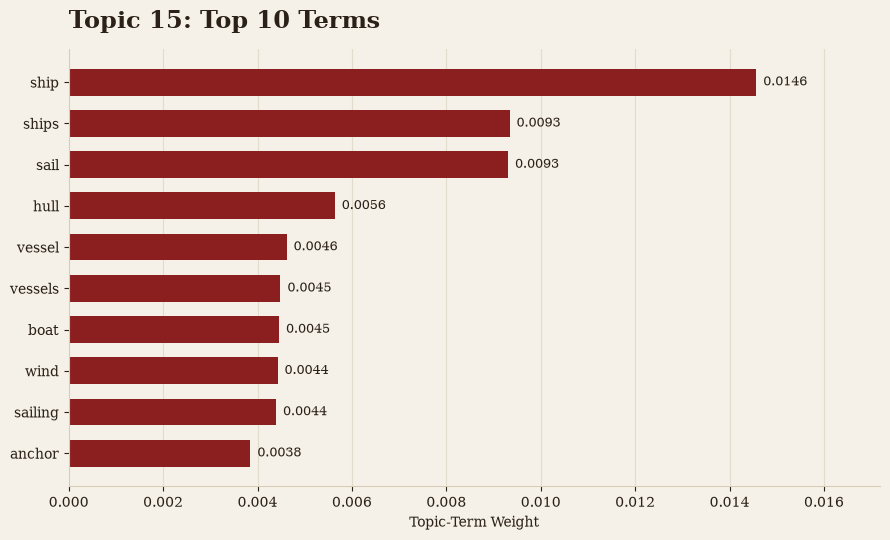

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/topic_words/topic_15_top_words.png

Generated 15 topic visualizations.


In [32]:
# Retrieve the top 10 words for every topic
topic_terms_df = lda_model.describeTopics(maxTermsPerTopic=10)

# Collect only the 15 topics and their 10 terms
topic_terms_rows = topic_terms_df.collect()

# Create output directory
IMAGE_DIR = Path.cwd() / "images" / "topic_words"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Configure visualization theme
plt.rcParams.update({
    "figure.facecolor": HISTORICAL_PALETTE["background"],
    "axes.facecolor": HISTORICAL_PALETTE["background"],
    "axes.edgecolor": HISTORICAL_PALETTE["grid"],
    "axes.labelcolor": HISTORICAL_PALETTE["text"],
    "text.color": HISTORICAL_PALETTE["text"],
    "xtick.color": HISTORICAL_PALETTE["text"],
    "ytick.color": HISTORICAL_PALETTE["text"],
    "grid.color": HISTORICAL_PALETTE["grid"],
    "font.family": "serif",
    "font.size": 10
})

# Generate one figure for each topic
for row in topic_terms_rows:

    topic_number = row["topic"] + 1

    # Convert vocabulary indices into actual words
    words = [
        vocabulary[index]
        for index in row["termIndices"]
    ]

    # Retrieve corresponding topic-term weights
    weights = list(row["termWeights"])

    # Reverse order so highest-weighted word appears at the top
    words = words[::-1]
    weights = weights[::-1]

    # Create figure
    fig, ax = plt.subplots(figsize=(9, 5.5))

    bars = ax.barh(
        words,
        weights,
        color=HISTORICAL_PALETTE["primary"],
        height=0.65
    )

    ax.set_title(
        f"Topic {topic_number}: Top 10 Terms",
        fontsize=17,
        fontweight="bold",
        loc="left",
        pad=15
    )

    ax.set_xlabel("Topic-Term Weight")

    # Add weight labels
    for bar, weight in zip(bars, weights):

        ax.annotate(
            f"{weight:.4f}",
            xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

    ax.grid(axis="x", alpha=0.6)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Allow room for value labels
    ax.set_xlim(0, max(weights) * 1.18)

    plt.tight_layout()

    # Save individual topic figure
    figure_path = IMAGE_DIR / f"topic_{topic_number:02d}_top_words.png"

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

    print("Saved:", figure_path.resolve())

print(f"\nGenerated {len(topic_terms_rows)} topic visualizations.")

## Representive Articles

In [33]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import Window
from pyspark.sql import functions as F

# Read saved article-topic distributions
article_topics_df = spark.read.parquet(TOPIC_DISTRIBUTIONS_DIR)

# Expand topic probability vectors into individual topic rows
article_topic_long_df = (
    article_topics_df
    .select(
        "page_id",
        "title",
        "crawl_depth",
        F.posexplode(
            vector_to_array("topicDistribution")
        ).alias("topic_index", "topic_probability")
    )
)

# Rank articles within each topic and crawl depth
ranking_window = (
    Window
    .partitionBy("topic_index", "crawl_depth")
    .orderBy(
        F.desc("topic_probability"),
        F.asc("title")
    )
)

# Retain the three most representative articles per topic and depth
representative_articles_df = (
    article_topic_long_df
    .withColumn(
        "article_rank",
        F.row_number().over(ranking_window)
    )
    .filter(F.col("article_rank") <= 3)
    .withColumn(
        "topic_number",
        F.col("topic_index") + 1
    )
    .select(
        "topic_number",
        "crawl_depth",
        "article_rank",
        "page_id",
        "title",
        "topic_probability"
    )
    .orderBy(
        "topic_number",
        "crawl_depth",
        "article_rank"
    )
)

# Save results for future analysis and network joins
REPRESENTATIVE_ARTICLES_DIR = (
    f"{LDA_DIR}/representative_articles_by_topic"
)

representative_articles_df.write.mode("overwrite").parquet(
    REPRESENTATIVE_ARTICLES_DIR
)

# Display results
representative_articles_df.show(90, truncate=False)

print("Saved representative articles to:", REPRESENTATIVE_ARTICLES_DIR)

+------------+-----------+------------+--------+---------------------------------------------+---------------------+
|topic_number|crawl_depth|article_rank|page_id |title                                        |topic_probability    |
+------------+-----------+------------+--------+---------------------------------------------+---------------------+
|1           |0          |1           |78188515|Battle of the Oxus (399)                     |0.5489802446583611   |
|1           |0          |2           |76896707|Yawm al-Nakhla                               |0.5395874968671888   |
|1           |0          |3           |78512718|First Battle of Eran                         |0.5199782837325918   |
|1           |1          |1           |249765  |Chandragupta II                              |0.999662608507297    |
|1           |1          |2           |22291855|Toramana                                     |0.9981124918568003   |
|1           |1          |3           |54755816|Eran boar inscri

### Visualization

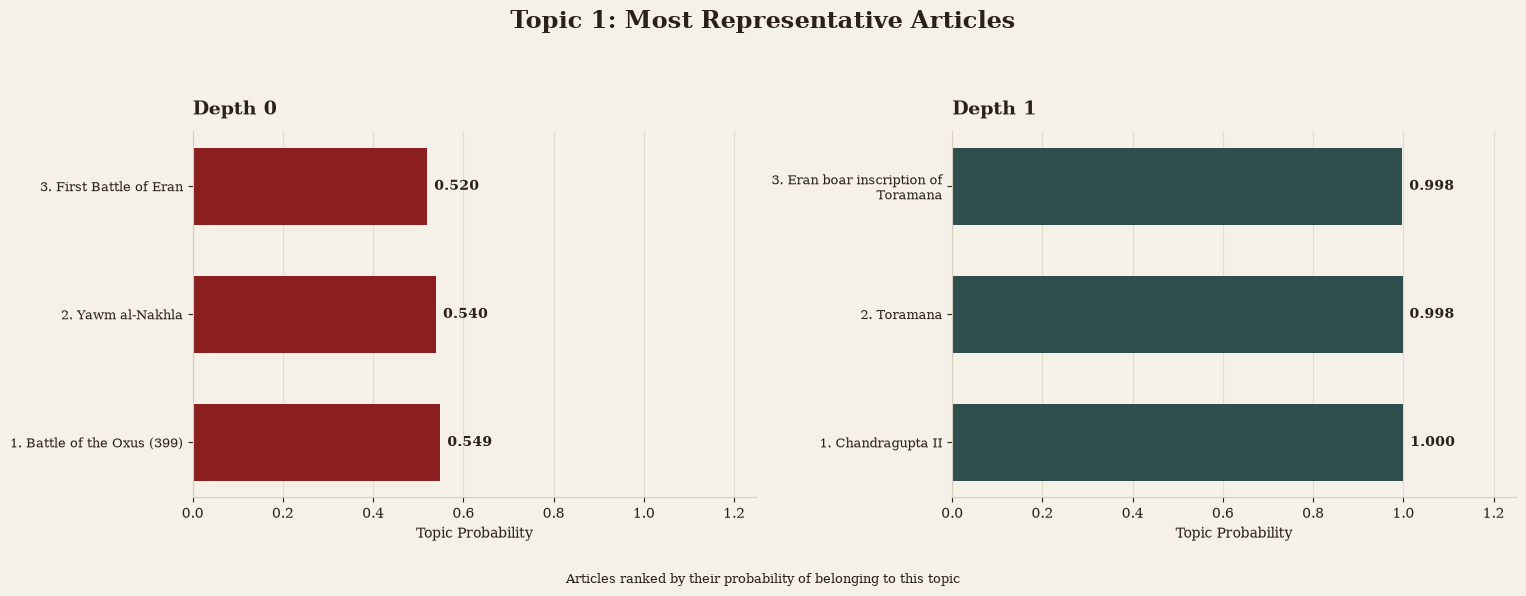

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_01_representative_articles.png


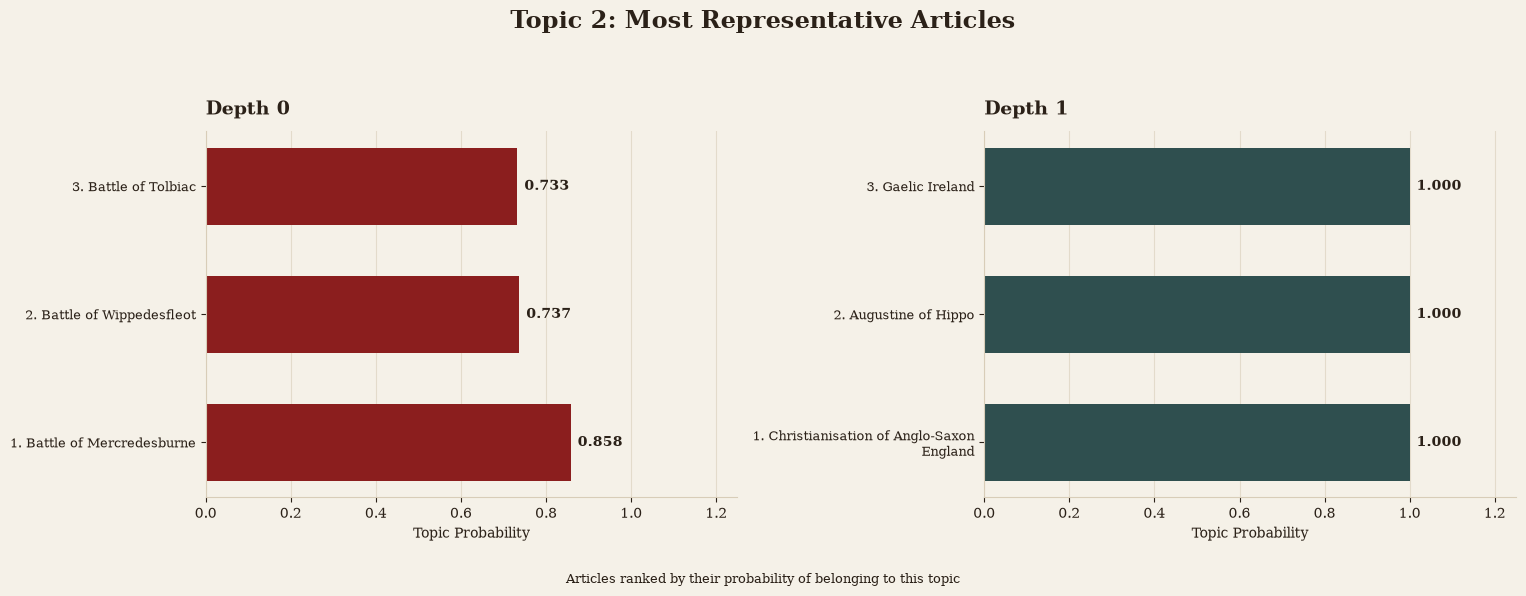

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_02_representative_articles.png


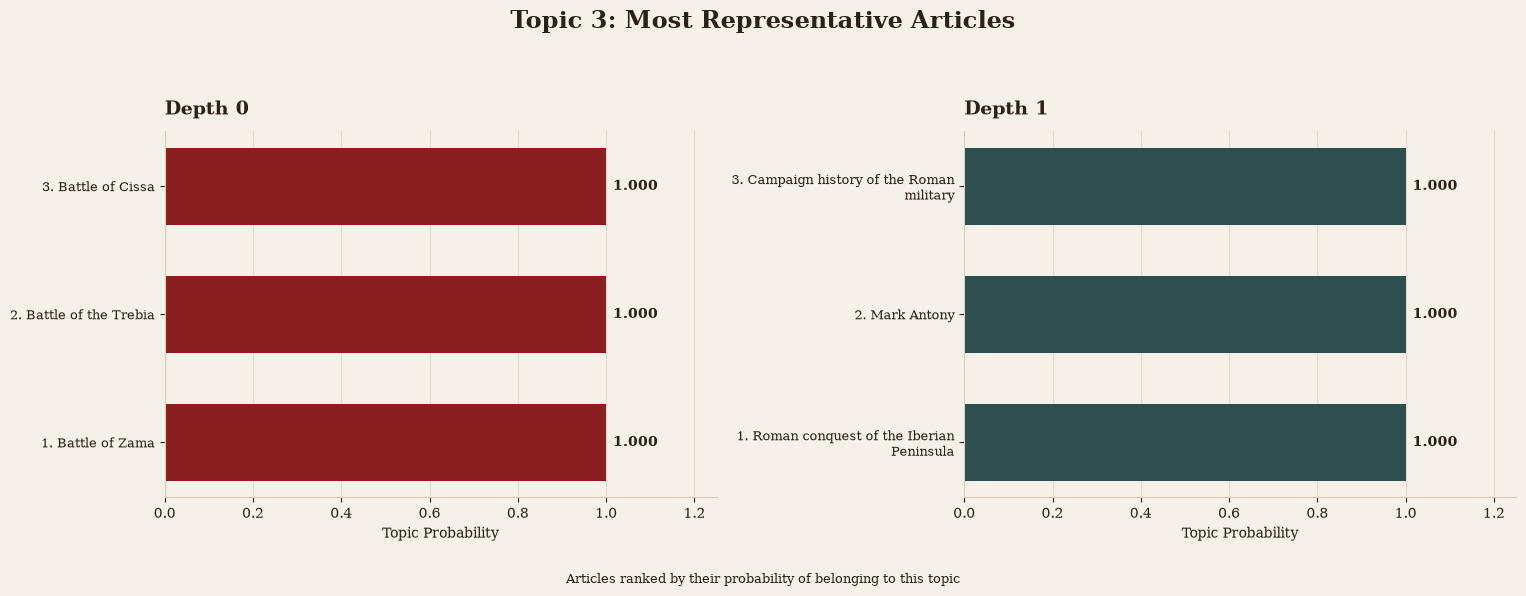

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_03_representative_articles.png


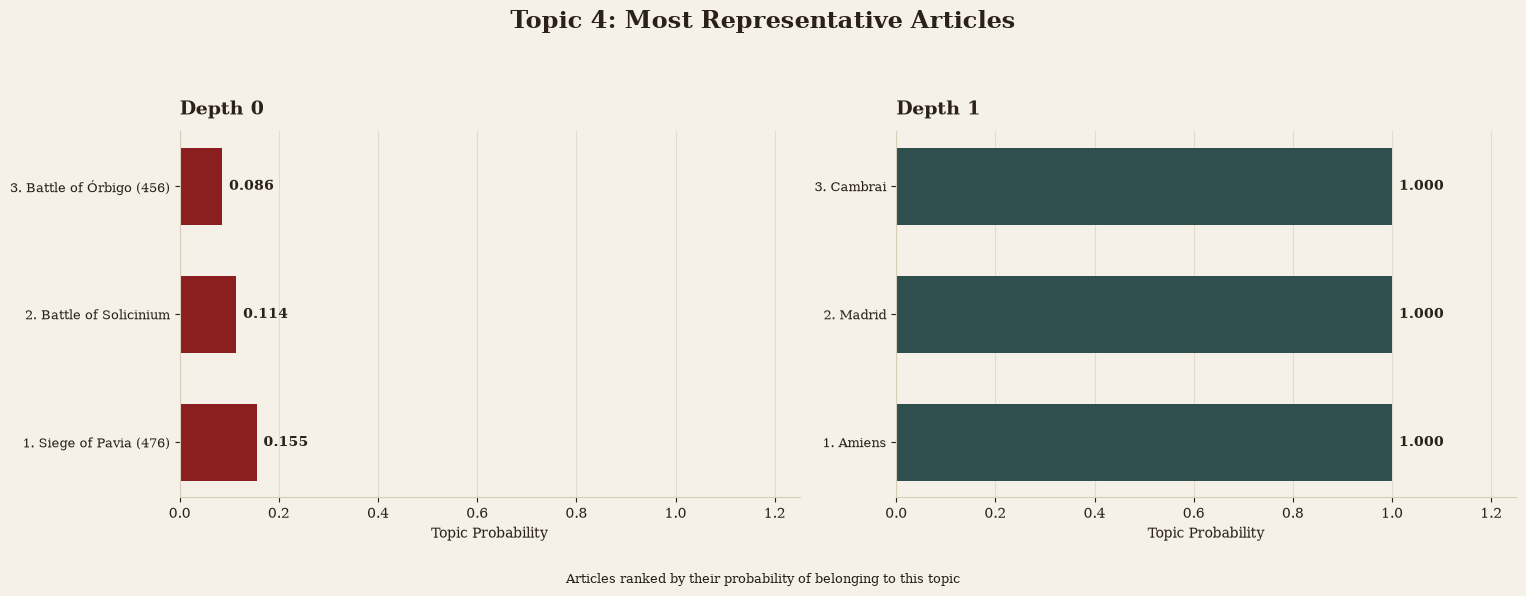

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_04_representative_articles.png


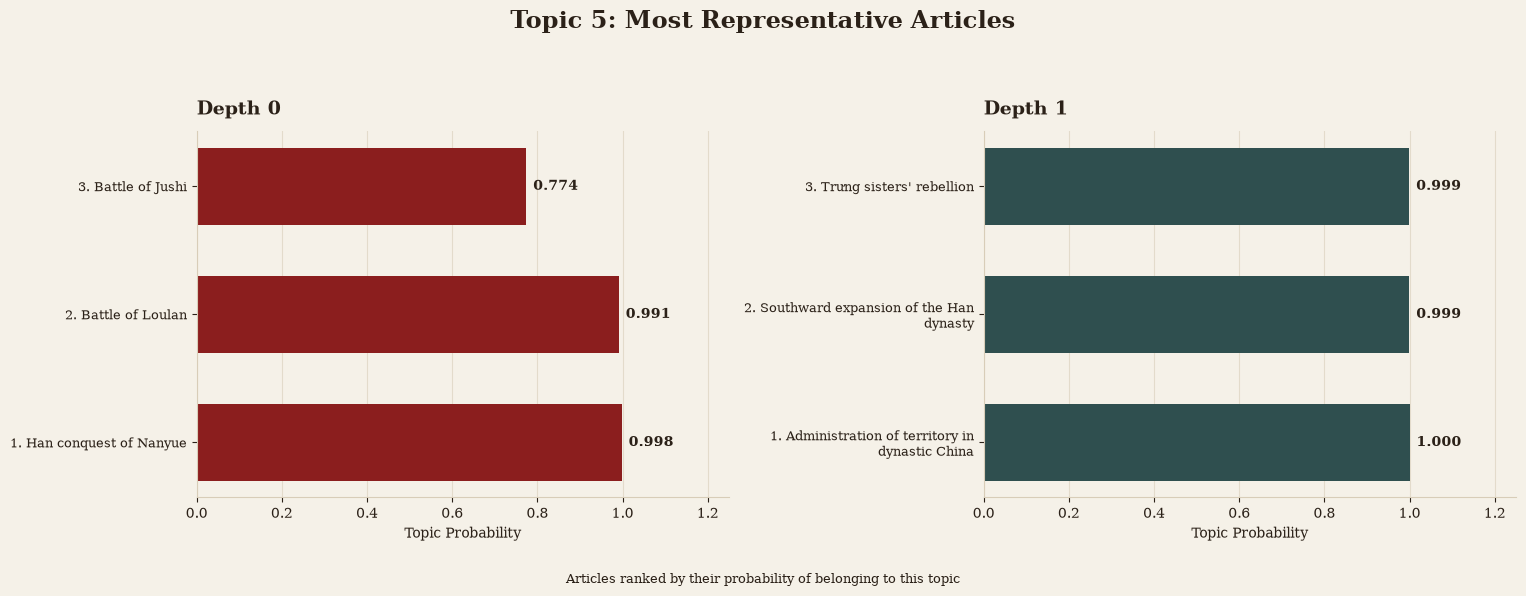

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_05_representative_articles.png


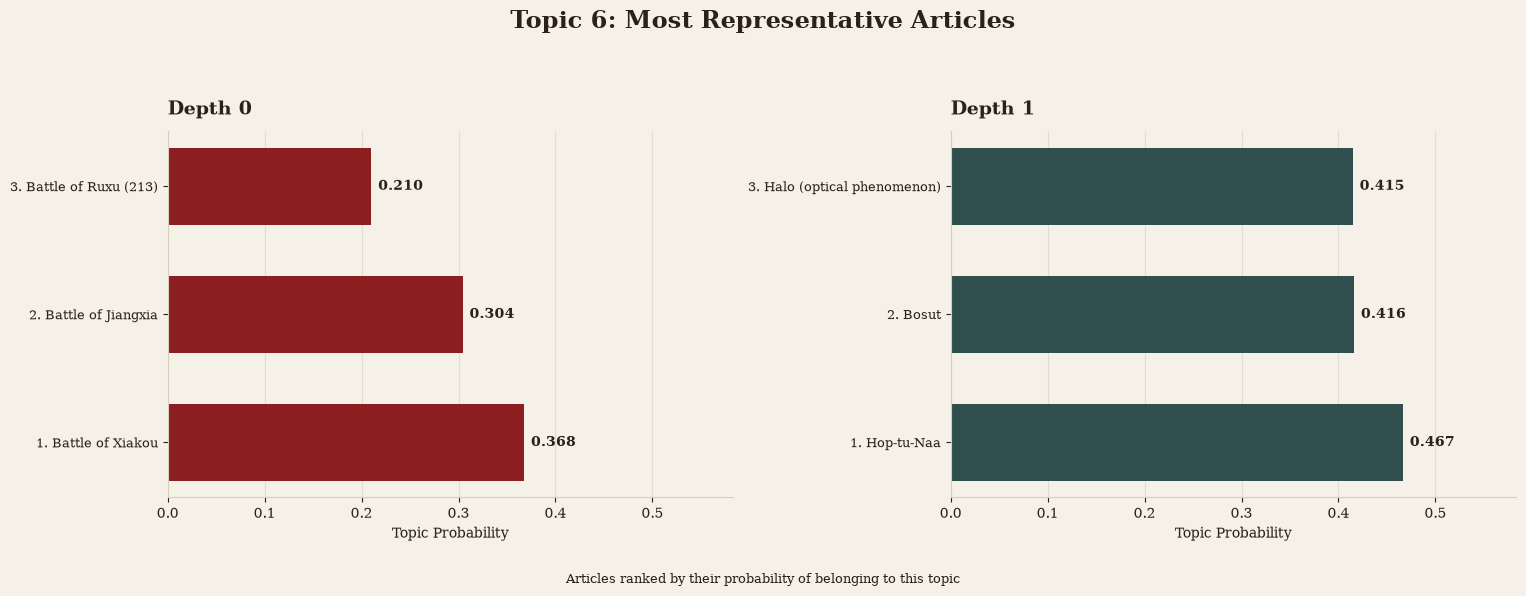

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_06_representative_articles.png


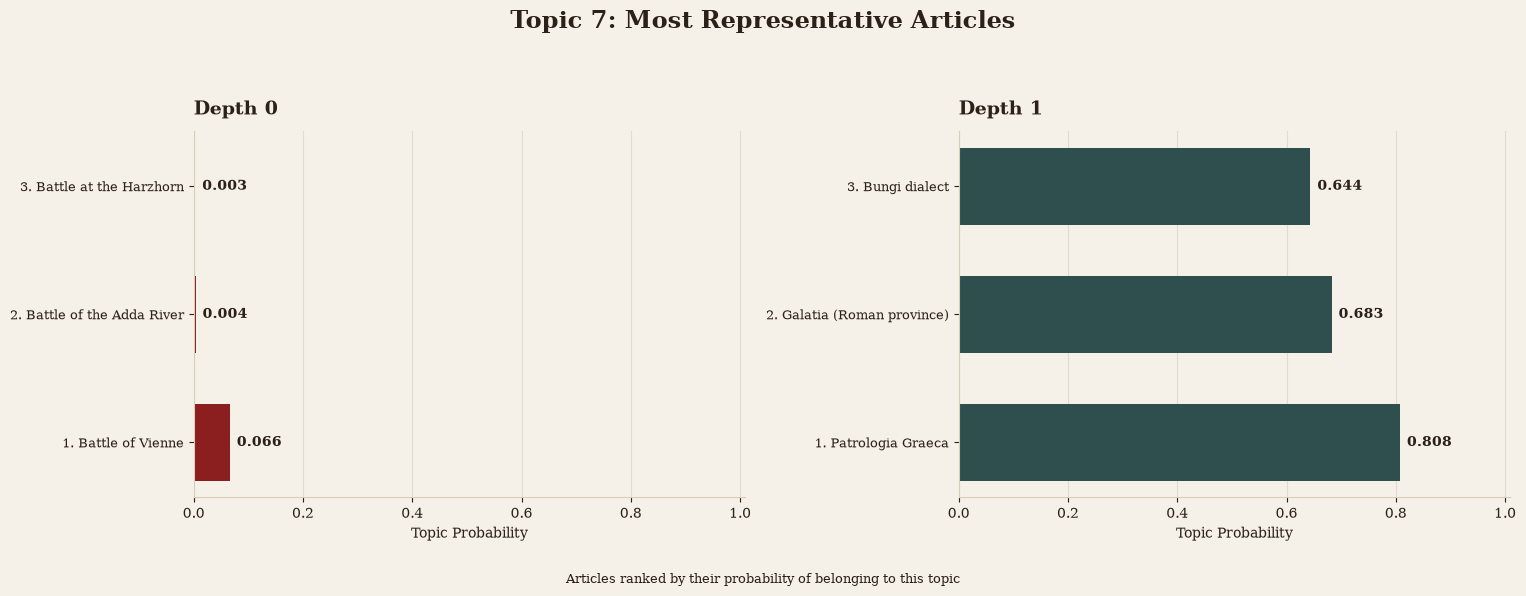

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_07_representative_articles.png


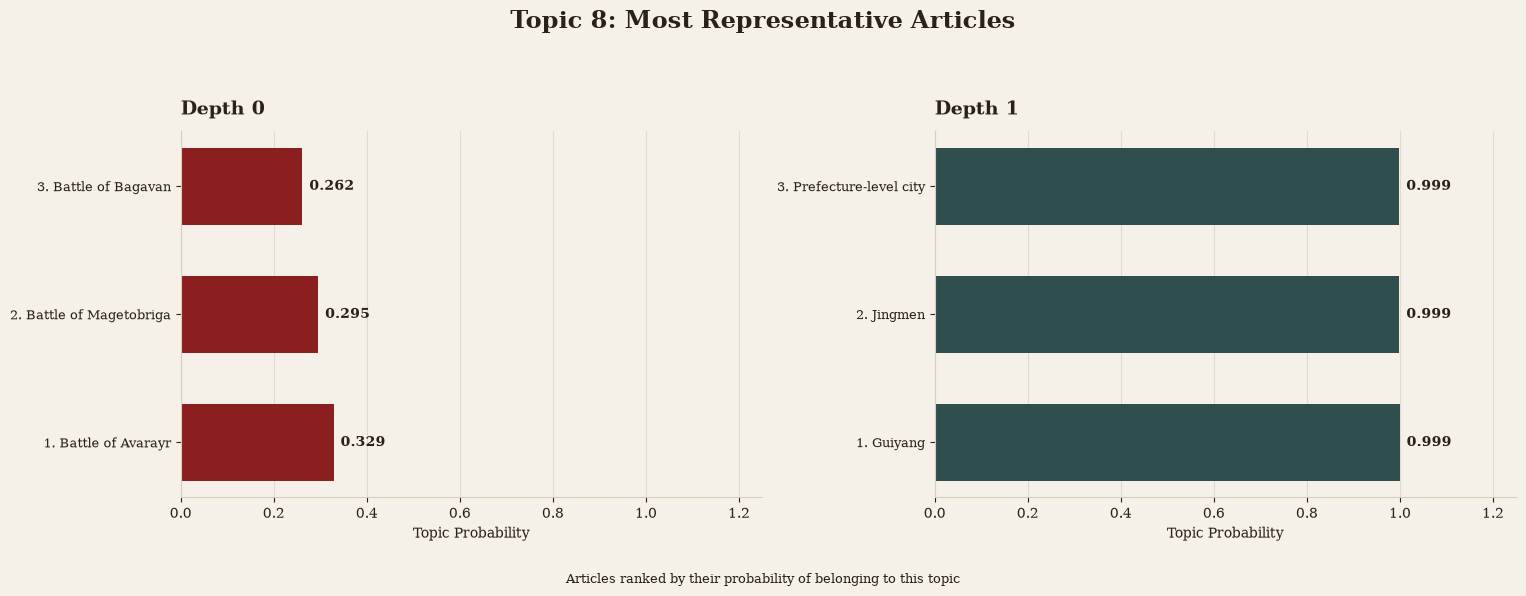

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_08_representative_articles.png


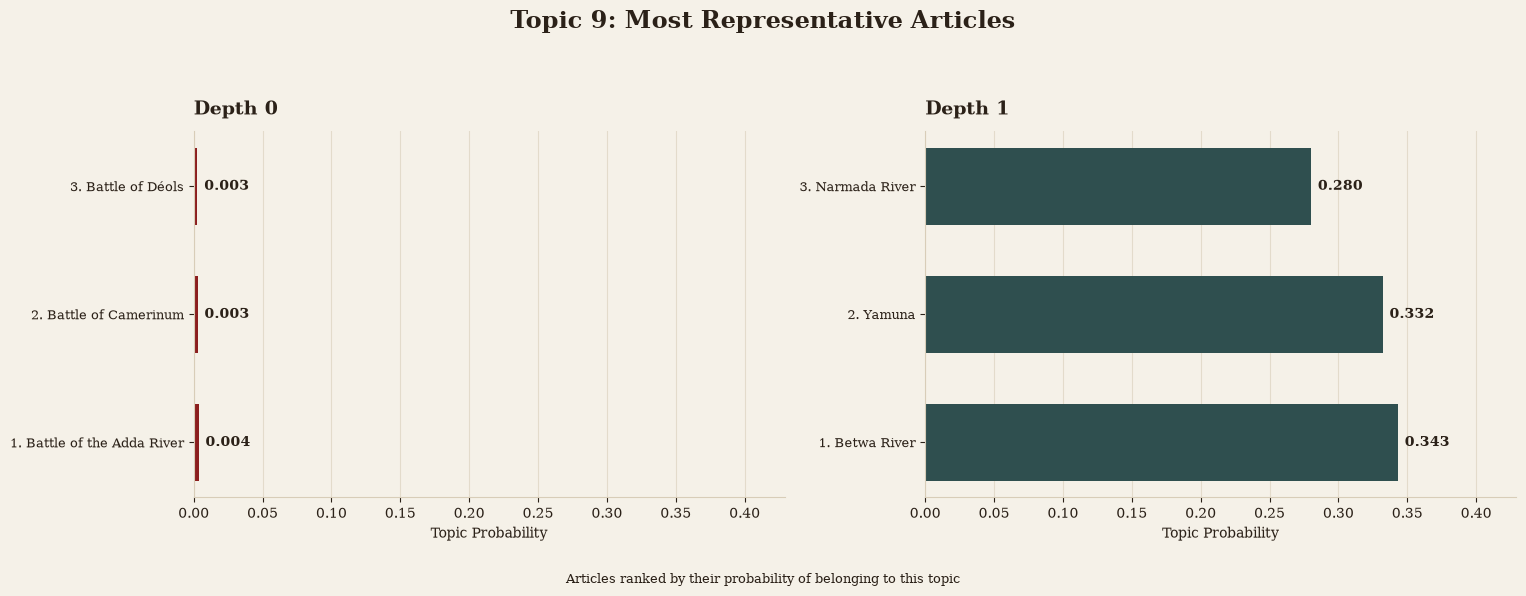

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_09_representative_articles.png


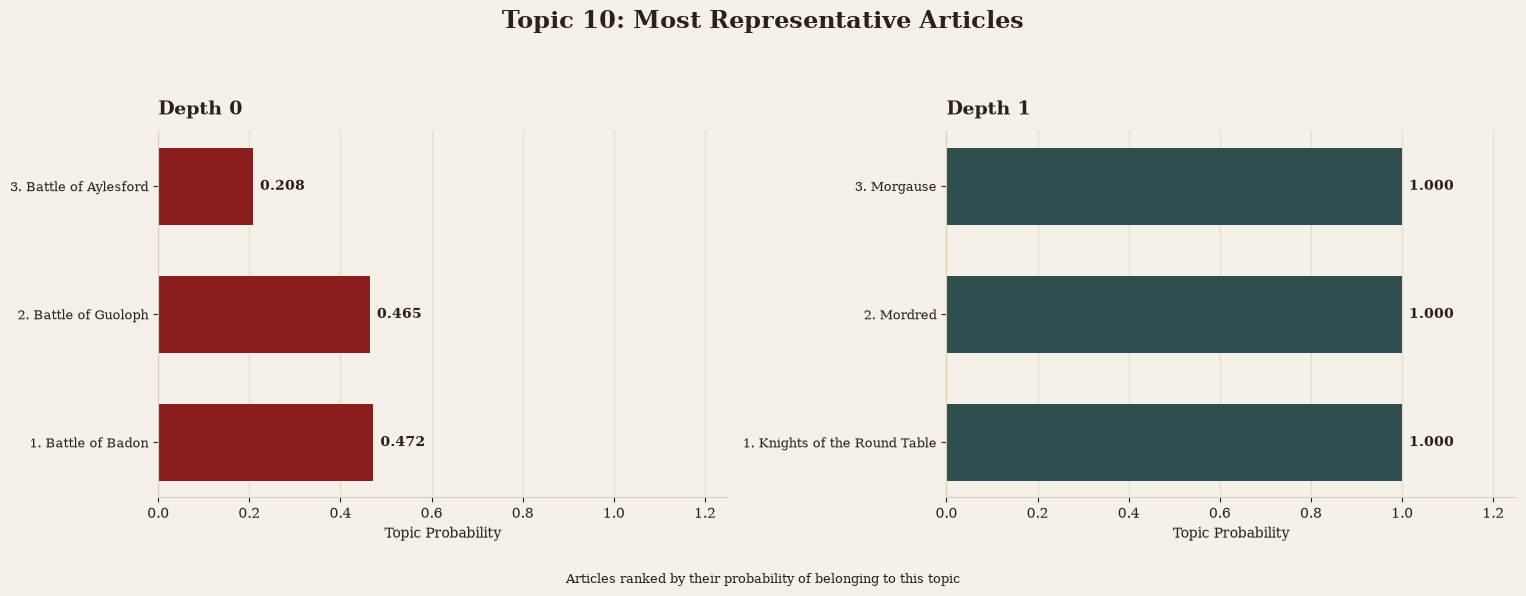

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_10_representative_articles.png


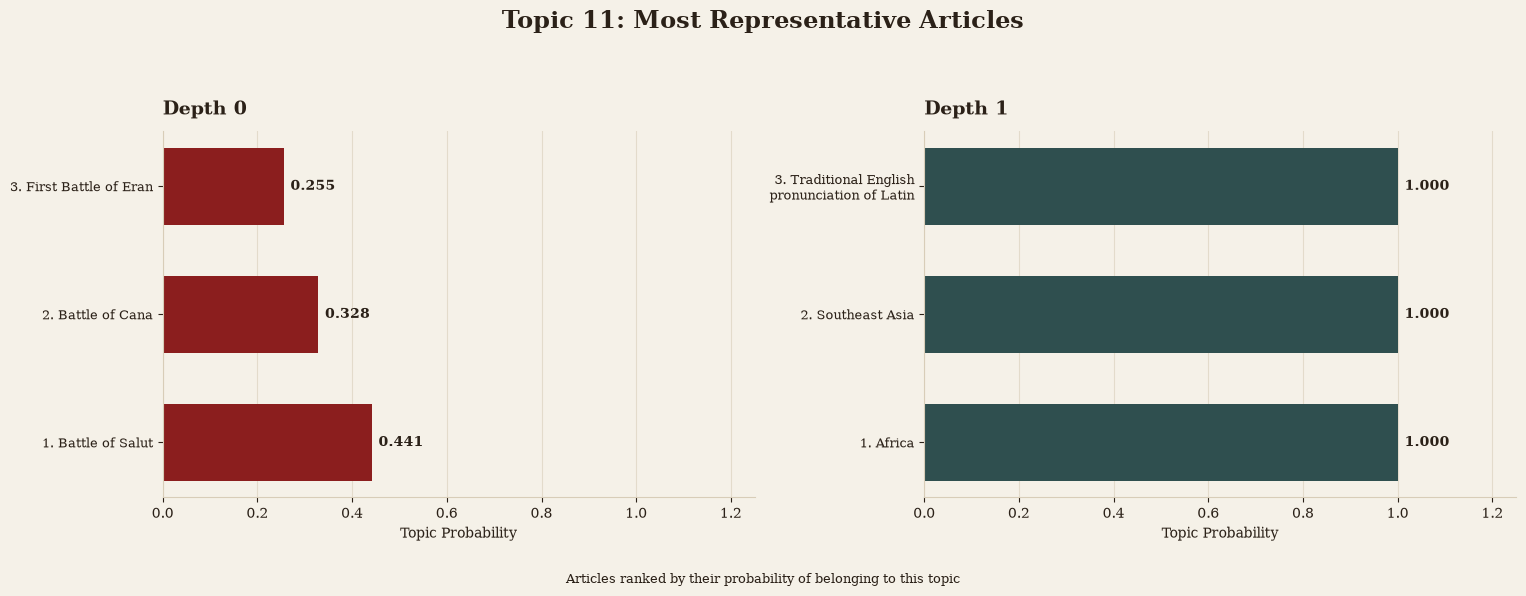

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_11_representative_articles.png


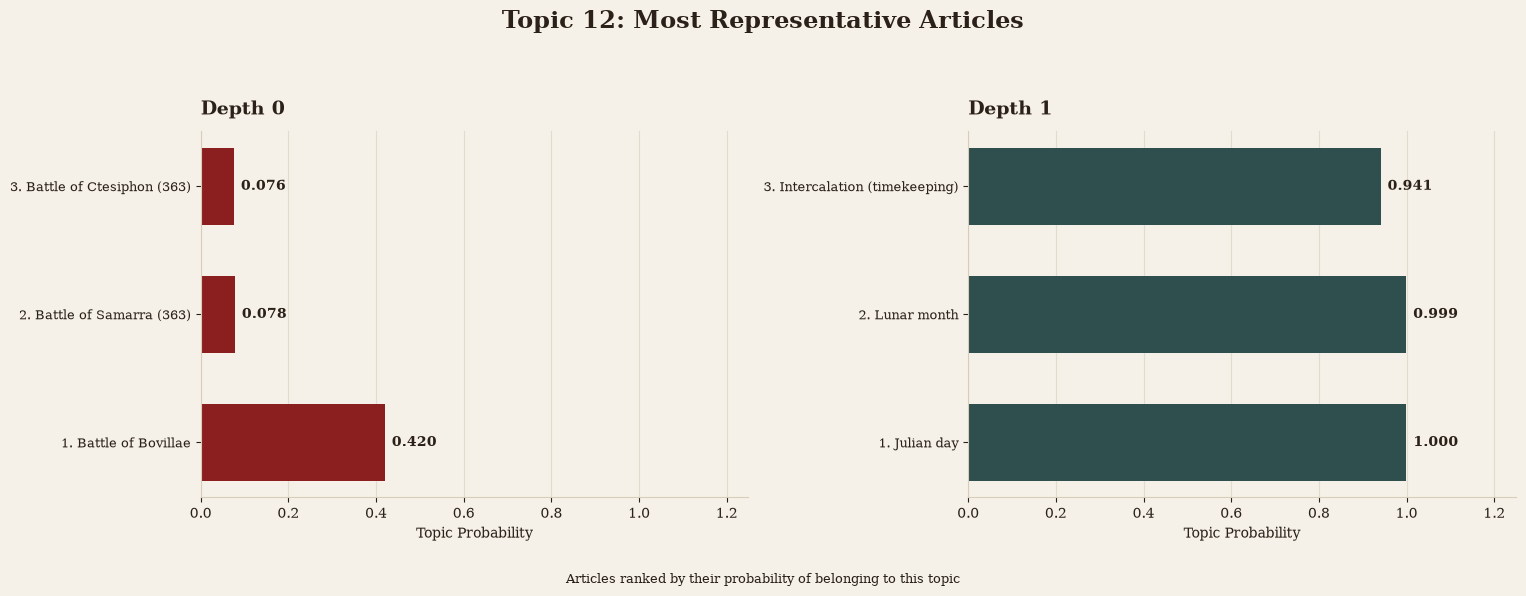

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_12_representative_articles.png


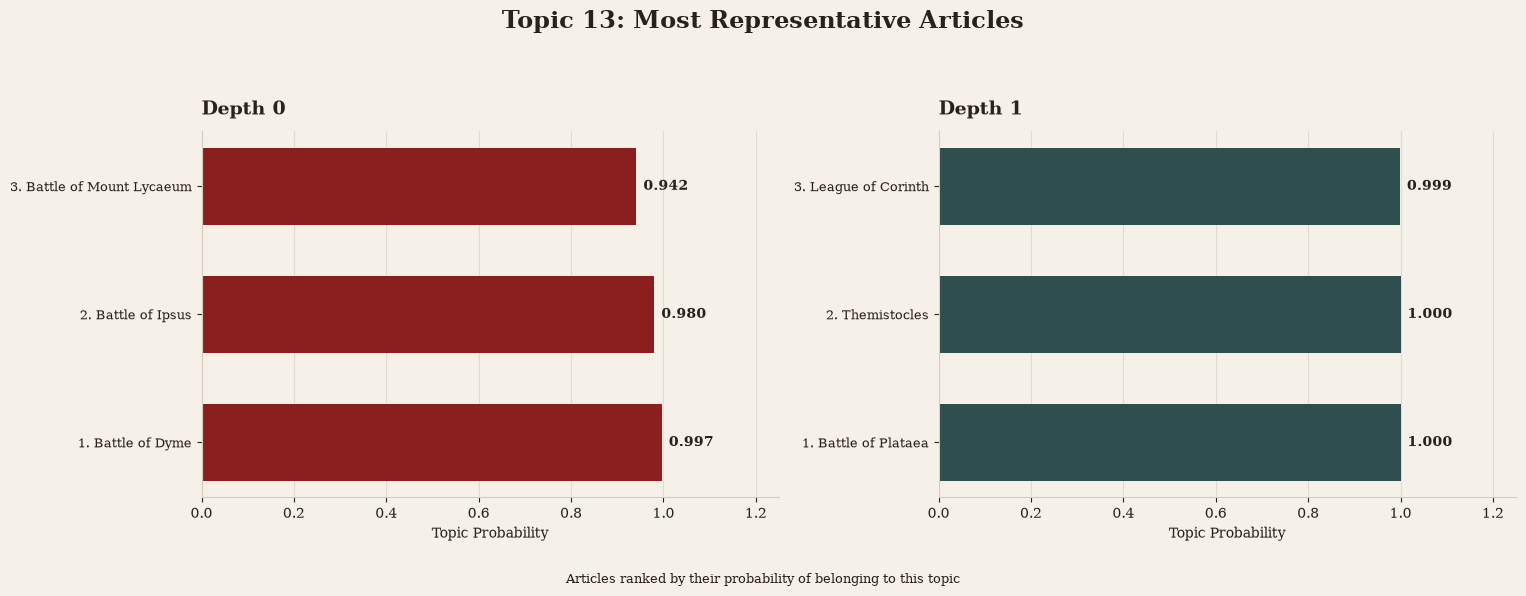

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_13_representative_articles.png


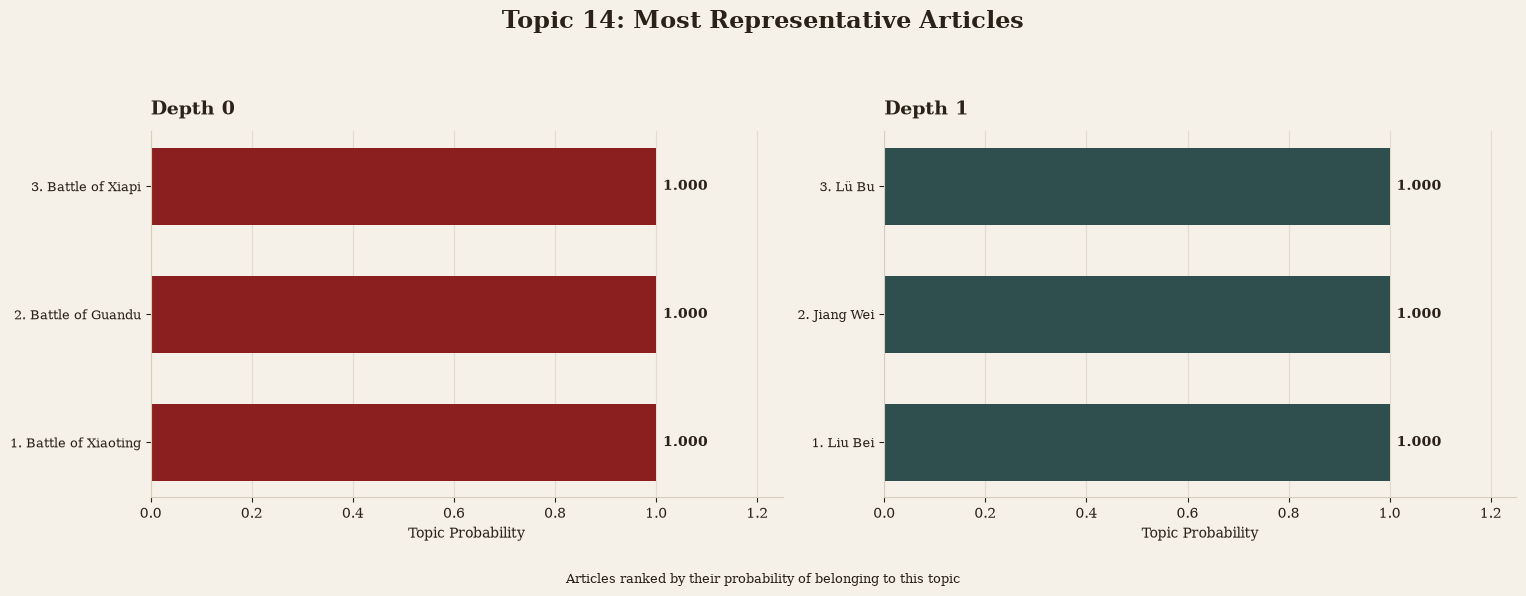

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_14_representative_articles.png


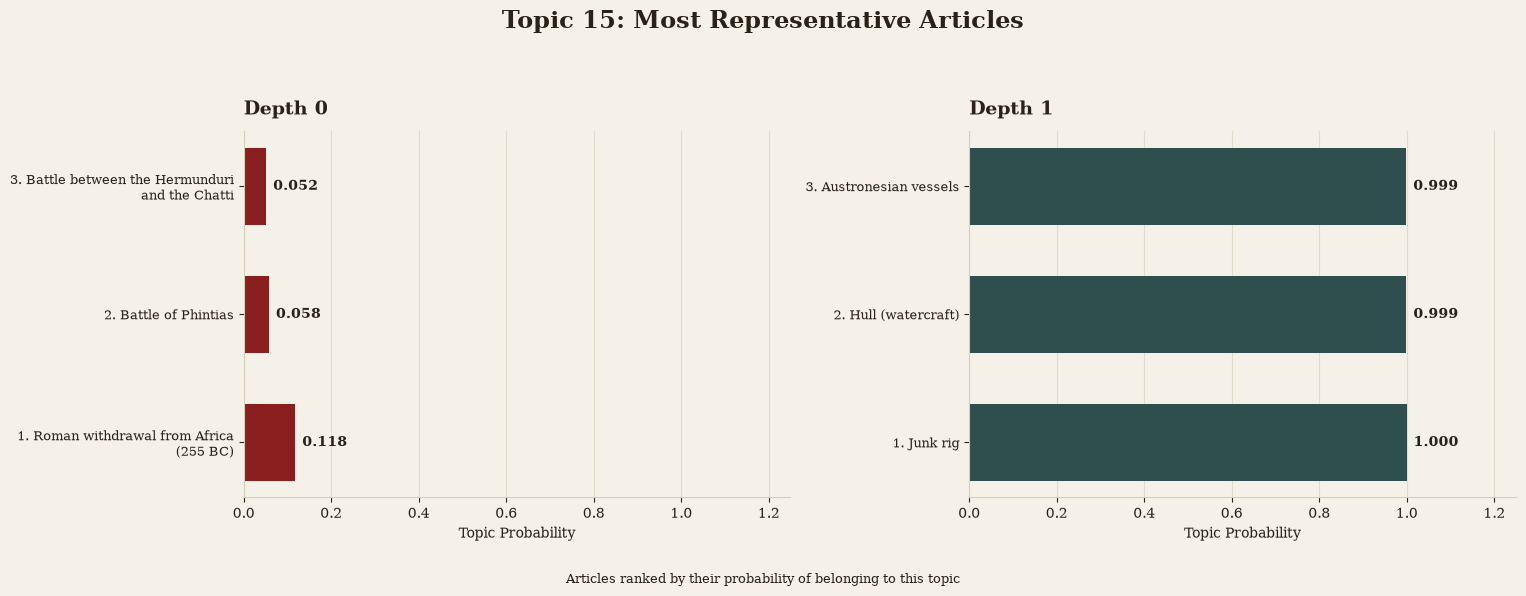

Saved: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_15_representative_articles.png

Generated 15 topic visualizations.


In [34]:
import matplotlib.pyplot as plt
import textwrap
from pathlib import Path

# Visualization settings
plt.rcParams.update({
    "figure.facecolor": HISTORICAL_PALETTE["background"],
    "axes.facecolor": HISTORICAL_PALETTE["background"],
    "axes.edgecolor": HISTORICAL_PALETTE["grid"],
    "axes.labelcolor": HISTORICAL_PALETTE["text"],
    "text.color": HISTORICAL_PALETTE["text"],
    "xtick.color": HISTORICAL_PALETTE["text"],
    "ytick.color": HISTORICAL_PALETTE["text"],
    "grid.color": HISTORICAL_PALETTE["grid"],
    "font.family": "serif",
    "font.size": 10
})

# Collect only the representative articles
representative_rows = (
    representative_articles_df
    .orderBy("topic_number", "crawl_depth", "article_rank")
    .collect()
)

# Create output directory
IMAGE_DIR = Path.cwd() / "images" / "representative_articles"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Group results by topic and crawl depth
topic_article_groups = {}

for row in representative_rows:

    topic_number = row["topic_number"]
    crawl_depth = row["crawl_depth"]

    if topic_number not in topic_article_groups:
        topic_article_groups[topic_number] = {}

    if crawl_depth not in topic_article_groups[topic_number]:
        topic_article_groups[topic_number][crawl_depth] = []

    topic_article_groups[topic_number][crawl_depth].append(row)


# Generate one figure per topic
for topic_number in sorted(topic_article_groups):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 6),
        sharex=True
    )

    fig.suptitle(
        f"Topic {topic_number}: Most Representative Articles",
        fontsize=17,
        fontweight="bold",
        color=HISTORICAL_PALETTE["text"],
        y=0.98
    )

    depth_settings = [
        (0, HISTORICAL_PALETTE["primary"]),
        (1, HISTORICAL_PALETTE["accent"])
    ]

    # Determine common probability scale for both panels
    all_probabilities = [
        row["topic_probability"]
        for depth in [0, 1]
        for row in topic_article_groups[topic_number].get(depth, [])
    ]

    x_limit = max(all_probabilities) * 1.25

    for ax, (depth, color) in zip(axes, depth_settings):

        articles = topic_article_groups[topic_number].get(depth, [])

        # Highest-ranked article appears at the top
        articles = sorted(
            articles,
            key=lambda row: row["article_rank"],
            reverse=True
        )

        article_titles = [
            textwrap.fill(
                f"{row['article_rank']}. {row['title']}",
                width=35
            )
            for row in articles
        ]

        probabilities = [
            row["topic_probability"]
            for row in articles
        ]

        if articles:

            bars = ax.barh(
                article_titles,
                probabilities,
                color=color,
                height=0.6
            )

            # Add probability labels
            for bar, probability in zip(bars, probabilities):

                ax.annotate(
                    f"{probability:.3f}",
                    xy=(
                        bar.get_width(),
                        bar.get_y() + bar.get_height() / 2
                    ),
                    xytext=(5, 0),
                    textcoords="offset points",
                    va="center",
                    fontsize=10,
                    fontweight="bold"
                )

            ax.invert_yaxis()

        else:
            ax.text(
                0.5,
                0.5,
                "No articles available",
                transform=ax.transAxes,
                ha="center",
                va="center"
            )

        ax.set_title(
            f"Depth {depth}",
            fontsize=14,
            fontweight="bold",
            loc="left",
            pad=12
        )

        ax.set_xlabel("Topic Probability")
        ax.set_xlim(0, x_limit)

        ax.grid(axis="x", alpha=0.6)
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(axis="y", labelsize=9)

    fig.text(
        0.5,
        0.025,
        "Articles ranked by their probability of belonging to this topic",
        ha="center",
        fontsize=9,
        color=HISTORICAL_PALETTE["text"]
    )

    plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.92])

    # Save individual topic visualization
    figure_path = IMAGE_DIR / (
        f"topic_{topic_number:02d}_representative_articles.png"
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

    print("Saved:", figure_path.resolve())

print(f"\nGenerated {len(topic_article_groups)} topic visualizations.")

## Topic Coherence

### Extract top 10 words per topic

In [41]:

topic_descriptions_df = lda_model.describeTopics(
    maxTermsPerTopic=10
)

topic_rows = topic_descriptions_df.collect()

topic_word_rows = []

for row in topic_rows:
    topic_number = row["topic"] + 1

    for rank, (term_index, term_weight) in enumerate(
        zip(row["termIndices"], row["termWeights"]),
        start=1
    ):
        topic_word_rows.append((
            topic_number,
            vocabulary[term_index],
            rank,
            float(term_weight)
        ))

values = []

for topic_number, word, rank, weight in topic_word_rows:
    safe_word = word.replace("'", "''")

    values.append(
        f"({topic_number}, '{safe_word}', {rank}, {weight})"
    )

values_sql = ", ".join(values)

topic_words_spark_df = spark.sql(f"""
    SELECT *
    FROM VALUES {values_sql}
    AS topic_words(topic_number, word, word_rank, term_weight)
""")

print("Number of topics:", topic_words_spark_df.select("topic_number").distinct().count())
print("Number of topic words:", topic_words_spark_df.count())

topic_words_spark_df.orderBy(
    "topic_number",
    "word_rank"
).show(150, truncate=False)
         


Number of topics: 15
Number of topic words: 150
+------------+----------+---------+---------------------+
|topic_number|word      |word_rank|term_weight          |
+------------+----------+---------+---------------------+
|1           |sasanian  |1        |0.0076092964515132085|
|1           |persian   |2        |0.0073359535391821390|
|1           |huns      |3        |0.0068344811062561630|
|1           |iranian   |4        |0.0058183034740214735|
|1           |varaha    |5        |0.0044149724807740180|
|1           |empire    |6        |0.0041060555912860080|
|1           |king      |7        |0.0040704700733459430|
|1           |iran      |8        |0.0039539087497932290|
|1           |india     |9        |0.0034540020275644390|
|1           |century   |10       |0.0034024658453101868|
|2           |one       |1        |0.0044446015610234770|
|2           |century   |2        |0.0042688263448926300|
|2           |roman     |3        |0.0039013232441913043|
|2           |used      

### Read the saved tokenized corpu

In [42]:
final_tokens_df = spark.read.parquet(FINAL_TOKENS_DIR)

coherence_articles_df = (
    final_tokens_df
    .select(
        "page_id",
        F.array_distinct("final_tokens").alias("tokens")
    )
)

# Total number of articles in the corpus
N_DOCUMENTS = coherence_articles_df.select(
    "page_id"
).distinct().count()

print("Articles in coherence corpus:", N_DOCUMENTS)

Articles in coherence corpus: 9015


### Calculate individual word frequencies

In [43]:
# Convert article tokens into individual word rows
article_words_df = (
    coherence_articles_df
    .select(
        "page_id",
        F.explode("tokens").alias("word")
    )
)

# Keep only words appearing in our 15 topics
topic_article_words_df = (
    article_words_df
    .join(
        topic_words_spark_df.select(
            "topic_number",
            "word"
        ),
        on="word",
        how="inner"
    )
    .select(
        "page_id",
        "topic_number",
        "word"
    )
)

# Count the number of articles containing each word
word_frequencies_df = (
    topic_article_words_df
    .groupBy("topic_number", "word")
    .agg(
        F.countDistinct("page_id").alias("word_document_count")
    )
)

word_frequencies_df.show(150, truncate=False)

+------------+----------+-------------------+
|topic_number|word      |word_document_count|
+------------+----------+-------------------+
|12          |calendar  |403                |
|10          |king      |4128               |
|4           |university|1434               |
|13          |persian   |1086               |
|8           |city      |4441               |
|1           |sasanian  |419                |
|7           |genoa     |142                |
|15          |ship      |761                |
|4           |war       |4823               |
|15          |vessels   |649                |
|12          |moon      |315                |
|15          |hull      |155                |
|12          |julian    |454                |
|2           |used      |4275               |
|6           |general   |3701               |
|12          |year      |3888               |
|14          |bei       |271                |
|14          |liu       |619                |
|9           |yamuna    |23       

### Calculate pairwise word co-occurrence

In [44]:
# Create every possible unique pair of words within each topic
word_pairs_df = (
    topic_words_spark_df.alias("a")
    .join(
        topic_words_spark_df.alias("b"),
        (
            (F.col("a.topic_number") == F.col("b.topic_number")) &
            (F.col("a.word") < F.col("b.word"))
        ),
        "inner"
    )
    .select(
        F.col("a.topic_number").alias("topic_number"),
        F.col("a.word").alias("word_1"),
        F.col("b.word").alias("word_2")
    )
)

# Find articles containing both words in each pair
article_word_pairs_df = (
    topic_article_words_df.alias("a")
    .join(
        topic_article_words_df.alias("b"),
        (
            (F.col("a.page_id") == F.col("b.page_id")) &
            (F.col("a.topic_number") == F.col("b.topic_number")) &
            (F.col("a.word") < F.col("b.word"))
        ),
        "inner"
    )
    .select(
        F.col("a.page_id").alias("page_id"),
        F.col("a.topic_number").alias("topic_number"),
        F.col("a.word").alias("word_1"),
        F.col("b.word").alias("word_2")
    )
)

# Count articles containing each word pair
pair_frequencies_df = (
    article_word_pairs_df
    .groupBy("topic_number", "word_1", "word_2")
    .agg(
        F.countDistinct("page_id").alias("pair_document_count")
    )
)

print("Number of possible word pairs:", word_pairs_df.count())
print("Number of observed word pairs:", pair_frequencies_df.count())

Number of possible word pairs: 675


Number of observed word pairs: 631


### Calculate NPMI

In [45]:
# Attach pair frequencies to all possible pairs
npmi_pairs_df = (
    word_pairs_df
    .join(
        pair_frequencies_df,
        on=["topic_number", "word_1", "word_2"],
        how="left"
    )
    .fillna({
        "pair_document_count": 0
    })
)

# Attach individual word frequencies for word 1
npmi_pairs_df = (
    npmi_pairs_df
    .join(
        word_frequencies_df
        .select(
            "topic_number",
            F.col("word").alias("word_1"),
            "word_document_count"
        )
        .withColumnRenamed(
            "word_document_count",
            "word_1_document_count"
        ),
        on=["topic_number", "word_1"],
        how="left"
    )
)

# Attach individual word frequencies for word 2
npmi_pairs_df = (
    npmi_pairs_df
    .join(
        word_frequencies_df
        .select(
            "topic_number",
            F.col("word").alias("word_2"),
            "word_document_count"
        )
        .withColumnRenamed(
            "word_document_count",
            "word_2_document_count"
        ),
        on=["topic_number", "word_2"],
        how="left"
    )
)

# Calculate probabilities
npmi_pairs_df = (
    npmi_pairs_df
    .withColumn(
        "p_xy",
        F.col("pair_document_count") / F.lit(N_DOCUMENTS)
    )
    .withColumn(
        "p_x",
        F.col("word_1_document_count") / F.lit(N_DOCUMENTS)
    )
    .withColumn(
        "p_y",
        F.col("word_2_document_count") / F.lit(N_DOCUMENTS)
    )
)

# Calculate NPMI, handling zero and perfect co-occurrence
npmi_pairs_df = npmi_pairs_df.withColumn(
    "npmi",
    F.when(
        F.col("pair_document_count") == 0,
        F.lit(-1.0)
    )
    .when(
        F.col("p_xy") == 1.0,
        F.lit(1.0)
    )
    .otherwise(
        F.log(
            F.col("p_xy") /
            (F.col("p_x") * F.col("p_y"))
        ) /
        (-F.log(F.col("p_xy")))
    )
)

npmi_pairs_df.select(
    "topic_number",
    "word_1",
    "word_2",
    "pair_document_count",
    "npmi"
).show(30, truncate=False)

+------------+---------+--------+-------------------+---------------------+
|topic_number|word_1   |word_2  |pair_document_count|npmi                 |
+------------+---------+--------+-------------------+---------------------+
|7           |genoa    |genoese |52                 |0.698733587334194    |
|7           |bungi    |genoa   |0                  |-1.0                 |
|8           |china    |turkish |115                |0.07917255039852908  |
|6           |battle   |huang   |201                |0.0792615722265562   |
|7           |catatonia|turkish |0                  |-1.0                 |
|6           |huang    |one     |256                |0.055641534155752015 |
|8           |armenian |china   |76                 |0.010562822839188012 |
|7           |first    |genoese |89                 |0.08806415726072223  |
|6           |battle   |sun     |592                |0.10435150959542959  |
|8           |chinese  |city    |806                |0.06991208382796536  |
|7          

### Calculate the final topic coherence scores

In [46]:
topic_coherence_df = (
    npmi_pairs_df
    .groupBy("topic_number")
    .agg(
        F.avg("npmi").alias("coherence_score"),
        F.count("*").alias("number_of_word_pairs"),
        F.sum(
            F.when(
                F.col("pair_document_count") > 0,
                1
            ).otherwise(0)
        ).alias("observed_word_pairs")
    )
    .orderBy("topic_number")
)

topic_coherence_df.show(15, truncate=False)

# Calculate overall average coherence
overall_coherence = (
    topic_coherence_df
    .agg(F.avg("coherence_score").alias("overall_coherence"))
    .first()["overall_coherence"]
)

print("Overall NPMI coherence:", round(overall_coherence, 4))

+------------+---------------------+--------------------+-------------------+
|topic_number|coherence_score      |number_of_word_pairs|observed_word_pairs|
+------------+---------------------+--------------------+-------------------+
|1           |0.2350824306863027   |45                  |45                 |
|2           |0.23360855402588884  |45                  |45                 |
|3           |0.19426196233421722  |45                  |45                 |
|4           |0.21184579086755978  |45                  |45                 |
|5           |0.2389886358244348   |45                  |45                 |
|6           |-0.023111210845744187|45                  |36                 |
|7           |-0.20729775566123299 |45                  |30                 |
|8           |0.16501048596481138  |45                  |45                 |
|9           |-0.21859925518080417 |45                  |25                 |
|10          |0.29042015213261463  |45                  |45     

Overall NPMI coherence: 0.1822


### Save the results

In [47]:
TOPIC_COHERENCE_DIR = f"{DIAGNOSTICS_DIR}/topic_coherence"

topic_coherence_df.write.mode("overwrite").parquet(
    f"{TOPIC_COHERENCE_DIR}/topic_scores"
)

npmi_pairs_df.write.mode("overwrite").parquet(
    f"{TOPIC_COHERENCE_DIR}/pairwise_scores"
)

print("Topic coherence results saved to:", TOPIC_COHERENCE_DIR)

Topic coherence results saved to: s3a://dsan6000-jg2292/ancient-battles/processed/nlp/topic_distribution_diagnostics/topic_coherence


## Visualize Topic Coherence

In [48]:
topic_coherence_df = spark.read.parquet(
    f"{TOPIC_COHERENCE_DIR}/topic_scores"
)

coherence_plot_df = (
    topic_coherence_df
    .orderBy("coherence_score", ascending=False)
    .toPandas()
)

# Calculate overall mean coherence
overall_coherence = coherence_plot_df["coherence_score"].mean()

display(coherence_plot_df)

print("Overall NPMI coherence:", round(overall_coherence, 4))

/home/ubuntu/dsan6000/DSAN600-AncientBattles/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,topic_number,coherence_score,number_of_word_pairs,observed_word_pairs
0,15,0.437024,45,45
1,14,0.417054,45,45
2,13,0.322567,45,45
3,10,0.290420,45,45
4,12,0.242283,45,45
5,5,0.238989,45,45
6,1,0.235082,45,45
7,2,0.233609,45,45
8,4,0.211846,45,45
9,3,0.194262,45,45


Overall NPMI coherence: 0.1822


### Visualize topic coherence

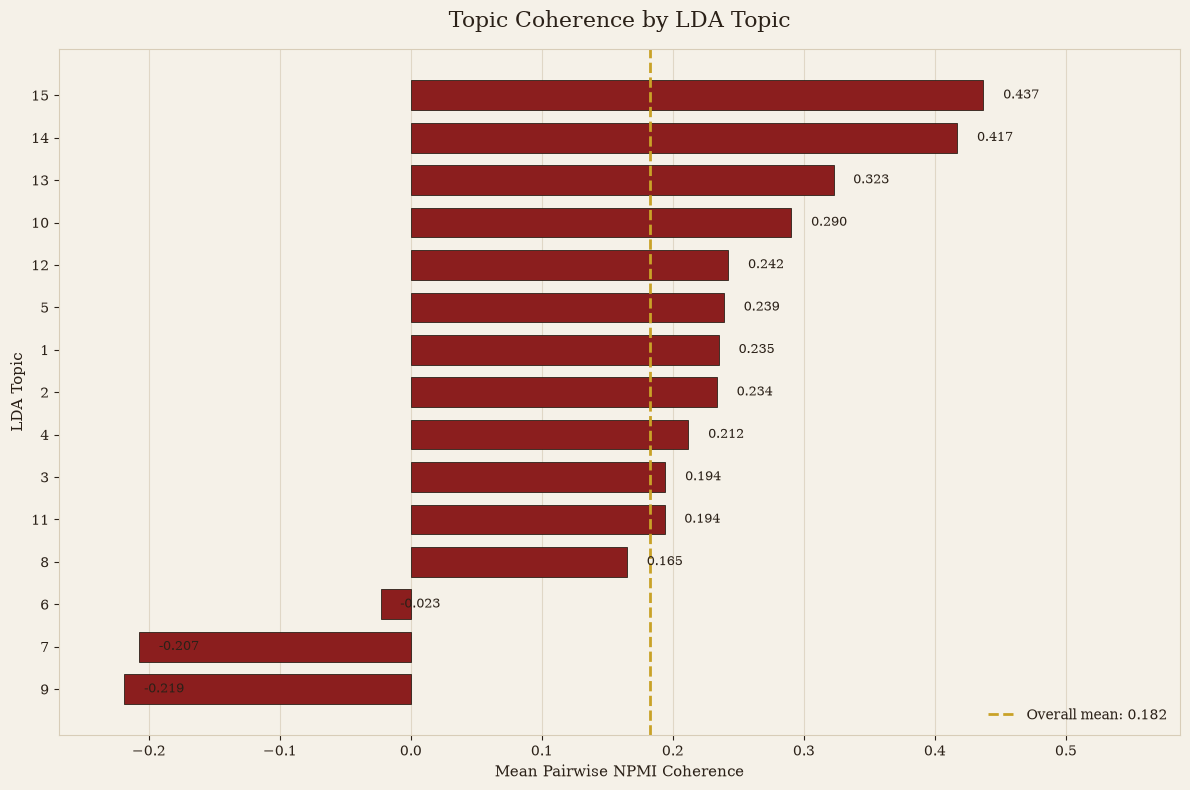

Visualization saved to: /home/ubuntu/dsan6000/DSAN600-AncientBattles/images/representative_articles/topic_coherence.png


In [49]:
# Sort topics from highest to lowest coherence
plot_df = coherence_plot_df.sort_values(
    "coherence_score",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 8))

# Horizontal bar chart
bars = ax.barh(
    plot_df["topic_number"].astype(str),
    plot_df["coherence_score"],
    color=HISTORICAL_PALETTE["primary"],
    edgecolor=HISTORICAL_PALETTE["text"],
    linewidth=0.6,
    height=0.7
)

# Overall mean reference line
ax.axvline(
    overall_coherence,
    color=HISTORICAL_PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Overall mean: {overall_coherence:.3f}"
)

# Add score labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9,
        color=HISTORICAL_PALETTE["text"]
    )

# Titles and labels
ax.set_title(
    "Topic Coherence by LDA Topic",
    fontsize=16,
    color=HISTORICAL_PALETTE["text"],
    pad=16
)

ax.set_xlabel(
    "Mean Pairwise NPMI Coherence",
    fontsize=11
)

ax.set_ylabel(
    "LDA Topic",
    fontsize=11
)

# Historical color palette
ax.set_facecolor(HISTORICAL_PALETTE["background"])
fig.patch.set_facecolor(HISTORICAL_PALETTE["background"])

ax.tick_params(
    axis="both",
    colors=HISTORICAL_PALETTE["text"]
)

ax.grid(
    axis="x",
    color=HISTORICAL_PALETTE["grid"],
    alpha=0.7
)

ax.set_axisbelow(True)

# Leave room for score labels
ax.set_xlim(
    min(-0.05, plot_df["coherence_score"].min() - 0.05),
    plot_df["coherence_score"].max() + 0.15
)

ax.legend(
    frameon=False,
    loc="lower right"
)

plt.tight_layout()

# Save visualization
coherence_image_path = IMAGE_DIR / "topic_coherence.png"

plt.savefig(
    coherence_image_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Visualization saved to:", coherence_image_path)

# LDA Topic Simularity

## # A. Imports and output directory

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pathlib import Path

# Create output directory
TOPIC_SIMILARITY_DIR = Path("images/topic_similarity")
TOPIC_SIMILARITY_DIR.mkdir(parents=True, exist_ok=True)

## Extract topic-word distributions

In [51]:
# Extract the LDA topic-word matrix
topic_word_matrix = lda_model.topicsMatrix().toArray()

# Normalize each topic into a probability distribution
topic_word_distributions = (
    topic_word_matrix /
    topic_word_matrix.sum(axis=0, keepdims=True)
)

NUM_TOPICS = topic_word_distributions.shape[1]

print("Number of topics:", NUM_TOPICS)
print("Vocabulary size:", topic_word_distributions.shape[0])
print("Distribution matrix shape:", topic_word_distributions.shape)

# Verify that each topic distribution sums to approximately 1
print(
    "Topic distribution sums:",
    np.round(topic_word_distributions.sum(axis=0), 6)
)

Number of topics: 15
Vocabulary size: 20000
Distribution matrix shape: (20000, 15)
Topic distribution sums: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Calculate symmetric KL divergence

In [52]:
def calculate_kl_divergence(p, q, epsilon=1e-12):

    # Smooth probabilities to avoid zeros
    p = p + epsilon
    q = q + epsilon

    # Renormalize probability distributions
    p = p / p.sum()
    q = q / q.sum()

    # Calculate KL divergence in both directions
    kl_pq = np.sum(p * np.log2(p / q))
    kl_qp = np.sum(q * np.log2(q / p))

    # Return symmetric KL divergence
    return kl_pq + kl_qp


# Initialize divergence matrix
topic_kl_matrix = np.zeros((NUM_TOPICS, NUM_TOPICS))

# Calculate divergence between every pair of topics
for i in range(NUM_TOPICS):

    for j in range(i + 1, NUM_TOPICS):

        divergence = calculate_kl_divergence(
            topic_word_distributions[:, i],
            topic_word_distributions[:, j]
        )

        # Store the same value in both directions
        topic_kl_matrix[i, j] = divergence
        topic_kl_matrix[j, i] = divergence


print("KL divergence matrix shape:", topic_kl_matrix.shape)

print(
    "Minimum divergence:",
    round(topic_kl_matrix[topic_kl_matrix > 0].min(), 4)
)

print(
    "Maximum divergence:",
    round(topic_kl_matrix.max(), 4)
)

KL divergence matrix shape: (15, 15)
Minimum divergence: 1.2587
Maximum divergence: 6.0989


## Create topic labels

In [53]:
top_terms = (
    lda_model
    .describeTopics(maxTermsPerTopic=3)
    .collect()
)

topic_labels = {}

for row in top_terms:

    topic_number = row["topic"] + 1

    words = [
        vocabulary[index]
        for index in row["termIndices"]
    ]

    topic_labels[row["topic"]] = (
        f"T{topic_number}\n" +
        " · ".join(words)
    )

print("Example topic labels:")

for topic, label in list(topic_labels.items())[:5]:
    print(label)

Example topic labels:
T1
sasanian · persian · huns
T2
one · century · roman
T3
roman · battle · army
T4
city · century · first
T5
han · jewish · chinese


## Build the topic similarity network

In [54]:
# --------------------------------------------------
# E. Build topic similarity network
# --------------------------------------------------

G = nx.Graph()

# Add topic nodes
for topic_number in range(NUM_TOPICS):

    G.add_node(
        topic_number,
        label=topic_labels[topic_number]
    )


# Number of closest topics to connect
TOP_K_NEIGHBORS = 2

# Connect each topic to its closest neighbors
for topic_number in range(NUM_TOPICS):

    divergences = topic_kl_matrix[topic_number].copy()

    # Exclude the topic itself
    divergences[topic_number] = np.inf

    # Find the topics with the lowest divergence
    nearest_topics = np.argsort(divergences)[
        :TOP_K_NEIGHBORS
    ]

    for neighbor in nearest_topics:

        divergence = topic_kl_matrix[
            topic_number,
            neighbor
        ]

        G.add_edge(
            topic_number,
            int(neighbor),
            weight=float(divergence)
        )


print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Number of connected components:", nx.number_connected_components(G))

Number of nodes: 15
Number of edges: 22
Number of connected components: 1


### Inspect topic connections

In [55]:
topic_edges = []

for topic_a, topic_b, attributes in G.edges(data=True):

    topic_edges.append({

        "topic_1": topic_a + 1,
        "topic_1_words": topic_labels[topic_a].replace("\n", " "),

        "topic_2": topic_b + 1,
        "topic_2_words": topic_labels[topic_b].replace("\n", " "),

        "kl_divergence": attributes["weight"]

    })


topic_edges_df = pd.DataFrame(topic_edges)

topic_edges_df = topic_edges_df.sort_values(
    "kl_divergence",
    ascending=True
).reset_index(drop=True)

display(topic_edges_df.round(4))

,topic_1,topic_1_words,topic_2,topic_2_words,kl_divergence
0,7,T7 genoa · cyprus · cypriot,9,T9 mumbai · narmada · yamuna,1.2587
1,2,T2 one · century · roman,11,T11 century · greek · ancient,1.4855
2,2,T2 one · century · roman,4,T4 city · century · first,1.5519
3,6,T6 sun · quan · manx,9,T9 mumbai · narmada · yamuna,1.8937
4,4,T4 city · century · first,11,T11 century · greek · ancient,1.9011
5,6,T6 sun · quan · manx,7,T7 genoa · cyprus · cypriot,2.0644
6,9,T9 mumbai · narmada · yamuna,12,T12 year · calendar · day,2.1738
7,7,T7 genoa · cyprus · cypriot,12,T12 year · calendar · day,2.1781
8,4,T4 city · century · first,8,T8 city · armenian · chinese,2.1965
9,8,T8 city · armenian · chinese,11,T11 century · greek · ancient,2.2358


### Plot the network

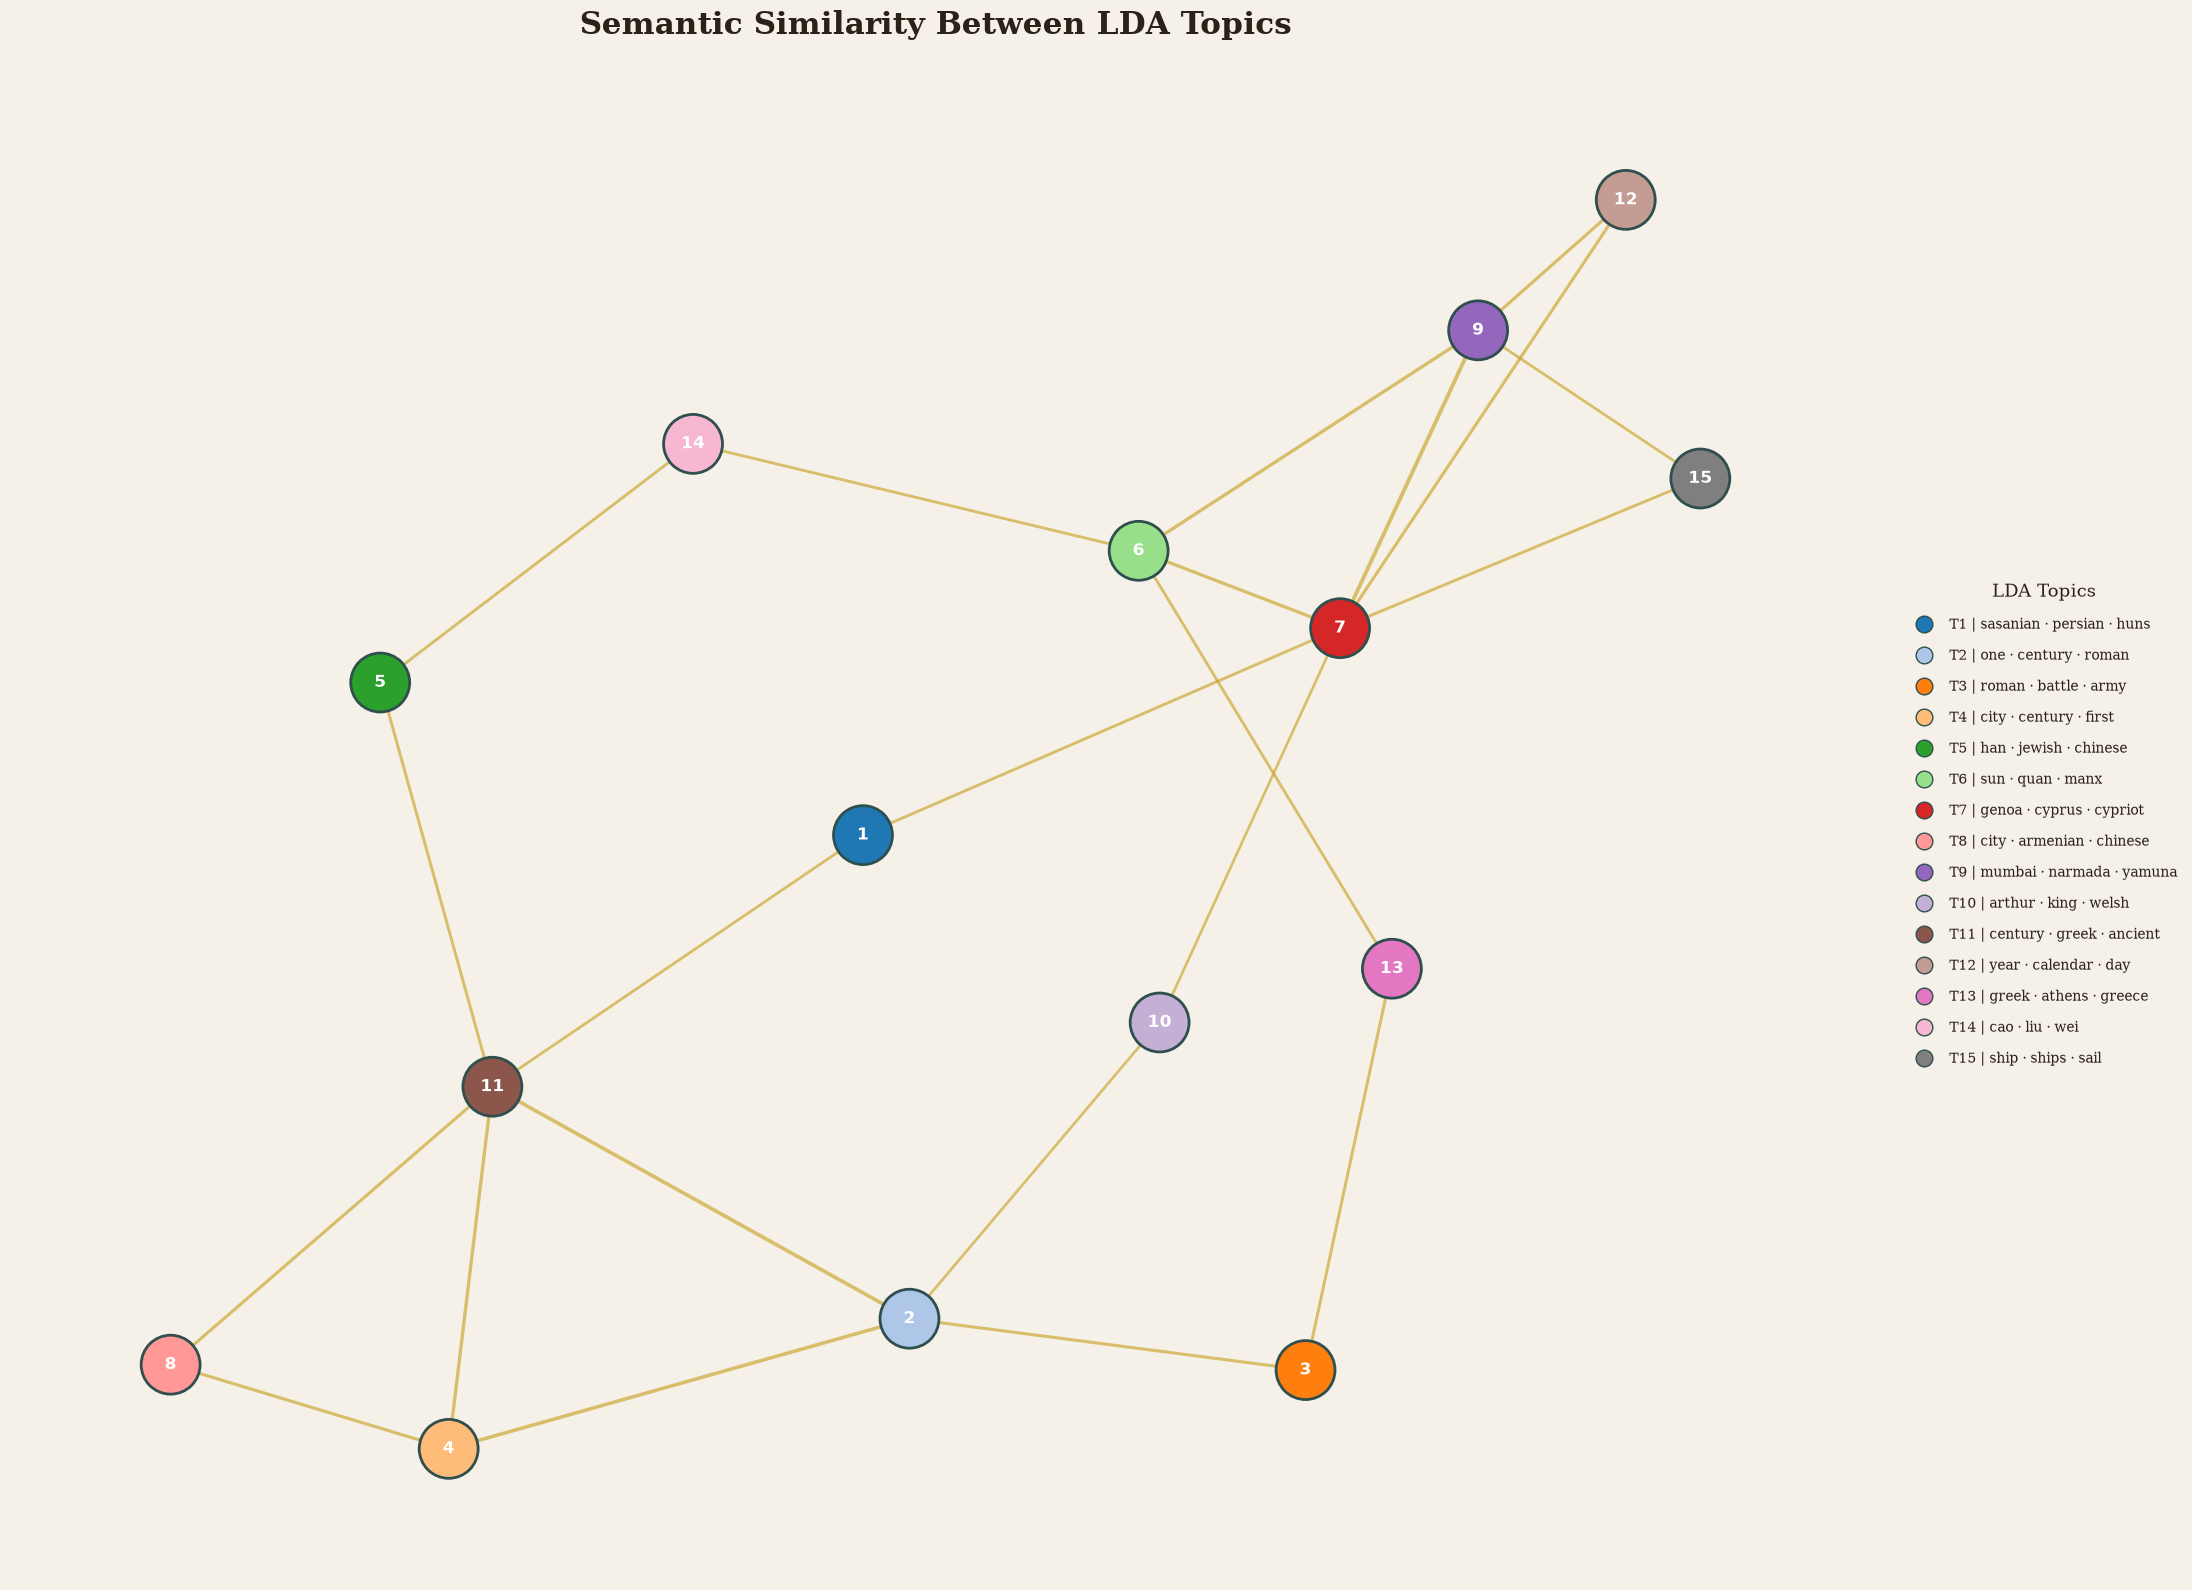

Saved visualization: images/topic_similarity/topic_similarity_network.png


In [58]:
fig, ax = plt.subplots(figsize=(22, 16))

# Generate network layout
positions = nx.spring_layout(
    G,
    weight="weight",
    seed=6000,
    k=1.8,
    iterations=300
)

# Generate 15 distinct topic colors
topic_colors = plt.cm.tab20(
    np.linspace(0, 14, NUM_TOPICS, dtype=int)
)

# Map each topic to its color
topic_color_map = {
    topic: topic_colors[topic]
    for topic in range(NUM_TOPICS)
}

# Extract edge widths
edge_widths = [
    1 + 4 / (1 + G[u][v]["weight"])
    for u, v in G.edges()
]

# Draw edges
nx.draw_networkx_edges(
    G,
    positions,
    ax=ax,
    width=edge_widths,
    edge_color=HISTORICAL_PALETTE["secondary"],
    alpha=0.65
)

# Draw topic nodes using individual colors
nx.draw_networkx_nodes(
    G,
    positions,
    ax=ax,
    node_size=1800,
    node_color=[
        topic_color_map[node]
        for node in G.nodes()
    ],
    edgecolors=HISTORICAL_PALETTE["accent"],
    linewidths=2
)

# Label nodes with topic numbers only
nx.draw_networkx_labels(
    G,
    positions,
    labels={
        topic: str(topic + 1)
        for topic in G.nodes()
    },
    ax=ax,
    font_size=12,
    font_weight="bold",
    font_color="white"
)

# Create legend entries
legend_handles = []

for topic in range(NUM_TOPICS):

    legend_handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=topic_color_map[topic],
            markeredgecolor=HISTORICAL_PALETTE["accent"],
            markersize=12,
            label=topic_labels[topic].replace("\n", " | ")
        )
    )

# Add legend to the right of the network
ax.legend(
    handles=legend_handles,
    title="LDA Topics",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=10,
    title_fontsize=13,
    frameon=False,
    labelspacing=1.2
)

# Title
ax.set_title(
    "Semantic Similarity Between LDA Topics",
    fontsize=22,
    fontweight="bold",
    color=HISTORICAL_PALETTE["text"],
    pad=25
)

# Remove axes
ax.axis("off")

# Set background
fig.patch.set_facecolor(HISTORICAL_PALETTE["background"])
ax.set_facecolor(HISTORICAL_PALETTE["background"])

plt.tight_layout()

# Save visualization
topic_network_path = (
    TOPIC_SIMILARITY_DIR /
    "topic_similarity_network.png"
)

plt.savefig(
    topic_network_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.5,
    facecolor=fig.get_facecolor()
)

plt.show()

plt.close()

print("Saved visualization:", topic_network_path)

### Heat Map

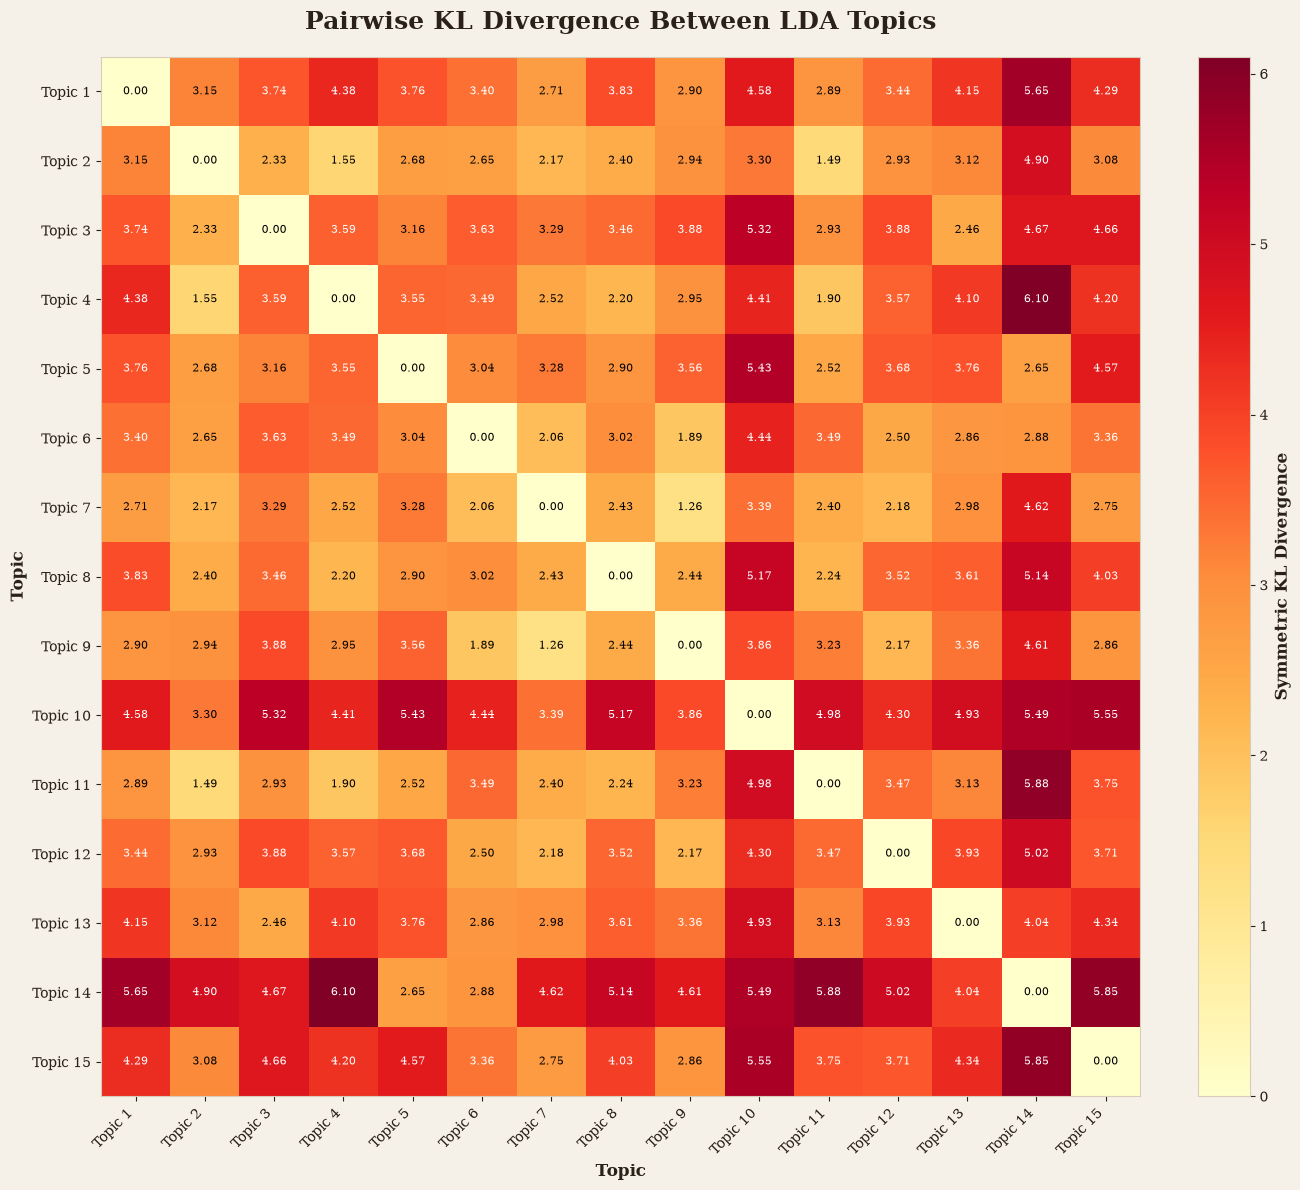

Saved heatmap: images/topic_similarity/topic_kl_divergence_heatmap.png


In [59]:

topic_names = [
    f"Topic {i + 1}"
    for i in range(NUM_TOPICS)
]


# --------------------------------------------------
# B. Create heatmap
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 12))

heatmap = ax.imshow(
    topic_kl_matrix,
    cmap="YlOrRd",
    interpolation="nearest"
)

# Add colorbar
cbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Symmetric KL Divergence",
    fontsize=12,
    fontweight="bold"
)

# Set topic labels
ax.set_xticks(range(NUM_TOPICS))
ax.set_yticks(range(NUM_TOPICS))

ax.set_xticklabels(
    topic_names,
    rotation=45,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(
    topic_names,
    fontsize=10
)

# Add divergence values to cells
for i in range(NUM_TOPICS):

    for j in range(NUM_TOPICS):

        value = topic_kl_matrix[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black" if value < topic_kl_matrix.max() * 0.55 else "white"
        )

# Title
ax.set_title(
    "Pairwise KL Divergence Between LDA Topics",
    fontsize=18,
    fontweight="bold",
    color=HISTORICAL_PALETTE["text"],
    pad=20
)

# Axis labels
ax.set_xlabel(
    "Topic",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Topic",
    fontsize=12,
    fontweight="bold"
)

# Background
fig.patch.set_facecolor(HISTORICAL_PALETTE["background"])
ax.set_facecolor(HISTORICAL_PALETTE["background"])

plt.tight_layout()


# --------------------------------------------------
# C. Save heatmap
# --------------------------------------------------

TOPIC_HEATMAP_DIR = Path("images/topic_similarity")
TOPIC_HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

topic_heatmap_path = (
    TOPIC_HEATMAP_DIR /
    "topic_kl_divergence_heatmap.png"
)

plt.savefig(
    topic_heatmap_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

plt.close()

print("Saved heatmap:", topic_heatmap_path)

# Network over Articles

In [73]:
# S3 raw data paths
RAW_DIR = f"{S3_BUCKET}/Raw"

ARTICLES_FILE = f"{RAW_DIR}/articles.jsonl"
VISITED_FILE = f"{RAW_DIR}/visited_pages.parquet"
FRONTIER_FILE = f"{RAW_DIR}/crawl_frontier.parquet"

# Load raw article data
articles_df = (
    spark.read
    .option("multiLine", "false")
    .json(ARTICLES_FILE)
)

# Load visited-page metadata
visited_df = spark.read.parquet(VISITED_FILE)

# Load crawl frontier
frontier_df = spark.read.parquet(FRONTIER_FILE)

# Inspect schemas
print("Articles:")
articles_df.printSchema()

print("Visited pages:")
visited_df.printSchema()

print("Crawl frontier:")
frontier_df.printSchema()

# Summarize raw article coverage
articles_df.filter(
    F.col("crawl_depth") <= 1
).agg(
    F.count("*").alias("article_records"),
    F.countDistinct("page_id").alias("unique_articles"),
    F.sum("outgoing_link_count").alias("total_outgoing_links"),
    F.sum(
        F.when(F.col("outgoing_links").isNull(), 1).otherwise(0)
    ).alias("articles_without_link_arrays")
).show()

Articles:
root
 |-- crawl_depth: long (nullable = true)
 |-- date: string (nullable = true)
 |-- discovered_from_page_id: long (nullable = true)
 |-- is_seed: boolean (nullable = true)
 |-- name: string (nullable = true)
 |-- outgoing_link_count: long (nullable = true)
 |-- outgoing_links: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- page_id: long (nullable = true)
 |-- source_url: string (nullable = true)
 |-- text: string (nullable = true)
 |-- title: string (nullable = true)
 |-- wikidata_id: string (nullable = true)

Visited pages:
root
 |-- page_id: long (nullable = true)
 |-- title: string (nullable = true)
 |-- crawl_depth: long (nullable = true)

Crawl frontier:
root
 |-- requested_title: string (nullable = true)
 |-- crawl_depth: long (nullable = true)
 |-- discovered_from_page_id: long (nullable = true)
 |-- source_url: string (nullable = true)
 |-- is_seed: boolean (nullable = true)
 |-- wikidata_id: string (nullable = true)
 |-- name: string 

+---------------+---------------+--------------------+----------------------------+
|article_records|unique_articles|total_outgoing_links|articles_without_link_arrays|
+---------------+---------------+--------------------+----------------------------+
|           9015|           9015|             2892687|                           0|
+---------------+---------------+--------------------+----------------------------+



## Build the directed edges

In [75]:
# Prepare node lookup using normalized article titles
nodes_lookup_df = nodes_df.select(
    F.col("page_id").alias("target_page_id"),
    F.col("title").alias("matched_target_title"),
    F.lower(F.trim(F.col("title"))).alias("normalized_target_title")
)

# Extract outgoing links from depth-0 and depth-1 articles
raw_edges_df = (
    articles_df
    .filter(F.col("crawl_depth") <= 1)
    .select(
        F.col("page_id").alias("source_page_id"),
        F.col("title").alias("source_title"),
        F.explode("outgoing_links").alias("target_title")
    )
    .withColumn(
        "normalized_target_title",
        F.lower(F.trim(F.col("target_title")))
    )
)

# Match link destinations to collected articles
edges_df = (
    raw_edges_df
    .join(
        nodes_lookup_df,
        on="normalized_target_title",
        how="inner"
    )
    .select(
        "source_page_id",
        "source_title",
        "target_page_id",
        F.col("matched_target_title").alias("target_title")
    )
    .dropDuplicates(["source_page_id", "target_page_id"])
)

## Load the collected article nodes and hyperlink edges

In [76]:
# ============================================
# 1. PREPARE THE NODE TABLE
# ============================================

# Keep only depth 0 and depth 1 articles
nodes_df = (
    visited_df
    .filter(F.col("crawl_depth") <= 1)
    .select("page_id", "title", "crawl_depth")
    .dropDuplicates(["page_id"])
)

# Create normalized titles for matching hyperlinks
nodes_lookup_df = nodes_df.select(
    F.col("page_id").alias("target_page_id"),
    F.lower(F.trim(F.col("title"))).alias("normalized_target_title")
)


# ============================================
# 2. EXTRACT ALL OUTGOING HYPERLINKS
# ============================================

raw_edges_df = (
    articles_df
    .filter(F.col("crawl_depth") <= 1)
    .select(
        F.col("page_id").alias("source_page_id"),
        F.explode("outgoing_links").alias("target_title")
    )
    .withColumn(
        "normalized_target_title",
        F.lower(F.trim(F.col("target_title")))
    )
)


# ============================================
# 3. MATCH LINKS TO NETWORK NODES
# ============================================

# Retain only hyperlinks where both source and destination
# are included in the 9,015-article corpus.

edges_df = (
    raw_edges_df
    .join(
        nodes_lookup_df,
        on="normalized_target_title",
        how="inner"
    )
    .select(
        "source_page_id",
        "target_page_id"
    )
    .dropDuplicates(["source_page_id", "target_page_id"])
    .filter(F.col("source_page_id") != F.col("target_page_id"))
)


# ============================================
# 4. CALCULATE NETWORK STATISTICS
# ============================================

node_count = nodes_df.count()
edge_count = edges_df.count()

network_density = edge_count / (node_count * (node_count - 1))

nodes_with_outgoing = edges_df.select(
    "source_page_id"
).distinct().count()

nodes_with_incoming = edges_df.select(
    "target_page_id"
).distinct().count()

print("WIKIPEDIA HYPERLINK NETWORK")
print("--------------------------------")
print(f"Number of nodes: {node_count:,}")
print(f"Number of directed edges: {edge_count:,}")
print(f"Network density: {network_density:.8f}")
print(f"Nodes with outgoing links: {nodes_with_outgoing:,}")
print(f"Nodes with incoming links: {nodes_with_incoming:,}")


# ============================================
# 5. SAVE NETWORK DATA TO S3
# ============================================

NETWORK_DIR = f"{S3_BUCKET}/processed/network"

nodes_df.write.mode("overwrite").parquet(
    f"{NETWORK_DIR}/nodes"
)

edges_df.write.mode("overwrite").parquet(
    f"{NETWORK_DIR}/edges"
)

print("\nNetwork data saved to:", NETWORK_DIR)

WIKIPEDIA HYPERLINK NETWORK
--------------------------------
Number of nodes: 9,015
Number of directed edges: 822,896
Network density: 0.01012655
Nodes with outgoing links: 8,976
Nodes with incoming links: 8,913



Network data saved to: s3a://dsan6000-jg2292/ancient-battles/processed/network


### Visualize Network

In [ ]:
# Select the 300 most connected articles
# based on total degree in the full network.

in_degree_df = (
    edges_df.groupBy("target_page_id")
    .count()
    .withColumnRenamed("count", "in_degree")
    .withColumnRenamed("target_page_id", "page_id")
)

out_degree_df = (
    edges_df.groupBy("source_page_id")
    .count()
    .withColumnRenamed("count", "out_degree")
    .withColumnRenamed("source_page_id", "page_id")
)

degree_df = (
    nodes_df.select("page_id", "title", "crawl_depth")
    .join(in_degree_df, on="page_id", how="left")
    .join(out_degree_df, on="page_id", how="left")
    .fillna(0, subset=["in_degree", "out_degree"])
    .withColumn(
        "total_degree",
        F.col("in_degree") + F.col("out_degree")
    )
)

top_nodes_df = (
    degree_df
    .orderBy(F.desc("total_degree"))
    .limit(300)
)

# Collect only the selected 500 nodes
top_nodes = top_nodes_df.toPandas()


# ============================================
# 3. EXTRACT EDGES BETWEEN SELECTED NODES
# ============================================

top_node_ids = top_nodes_df.select("page_id")

sample_edges_df = (
    edges_df
    .join(
        top_node_ids.withColumnRenamed("page_id", "source_page_id"),
        on="source_page_id",
        how="inner"
    )
    .join(
        top_node_ids.withColumnRenamed("page_id", "target_page_id"),
        on="target_page_id",
        how="inner"
    )
)

sample_edges = sample_edges_df.toPandas()

G_sample = nx.DiGraph()

# Add selected nodes and their attributes
for _, row in top_nodes.iterrows():
    G_sample.add_node(
        int(row["page_id"]),
        title=row["title"],
        degree=int(row["total_degree"]),
        crawl_depth=int(row["crawl_depth"])
    )

# Only add edges where BOTH endpoints are selected nodes
selected_node_ids = set(G_sample.nodes())

for source, target in zip(
    sample_edges["source_page_id"],
    sample_edges["target_page_id"]
):
    source = int(source)
    target = int(target)

    if source in selected_node_ids and target in selected_node_ids:
        G_sample.add_edge(source, target)

# Verify graph construction
missing_depth = [
    node for node, data in G_sample.nodes(data=True)
    if "crawl_depth" not in data
]

print("Total graph nodes:", G_sample.number_of_nodes())
print("Nodes missing crawl depth:", len(missing_depth))




/home/ubuntu/dsan6000/DSAN600-AncientBattles/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ubuntu/dsan6000/DSAN600-AncientBattles/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Total graph nodes: 300
Nodes missing crawl depth: 0


### BUILD THE VISUALIZATION GRAPH

Original battle articles in visualization: 9
Context articles in visualization: 291


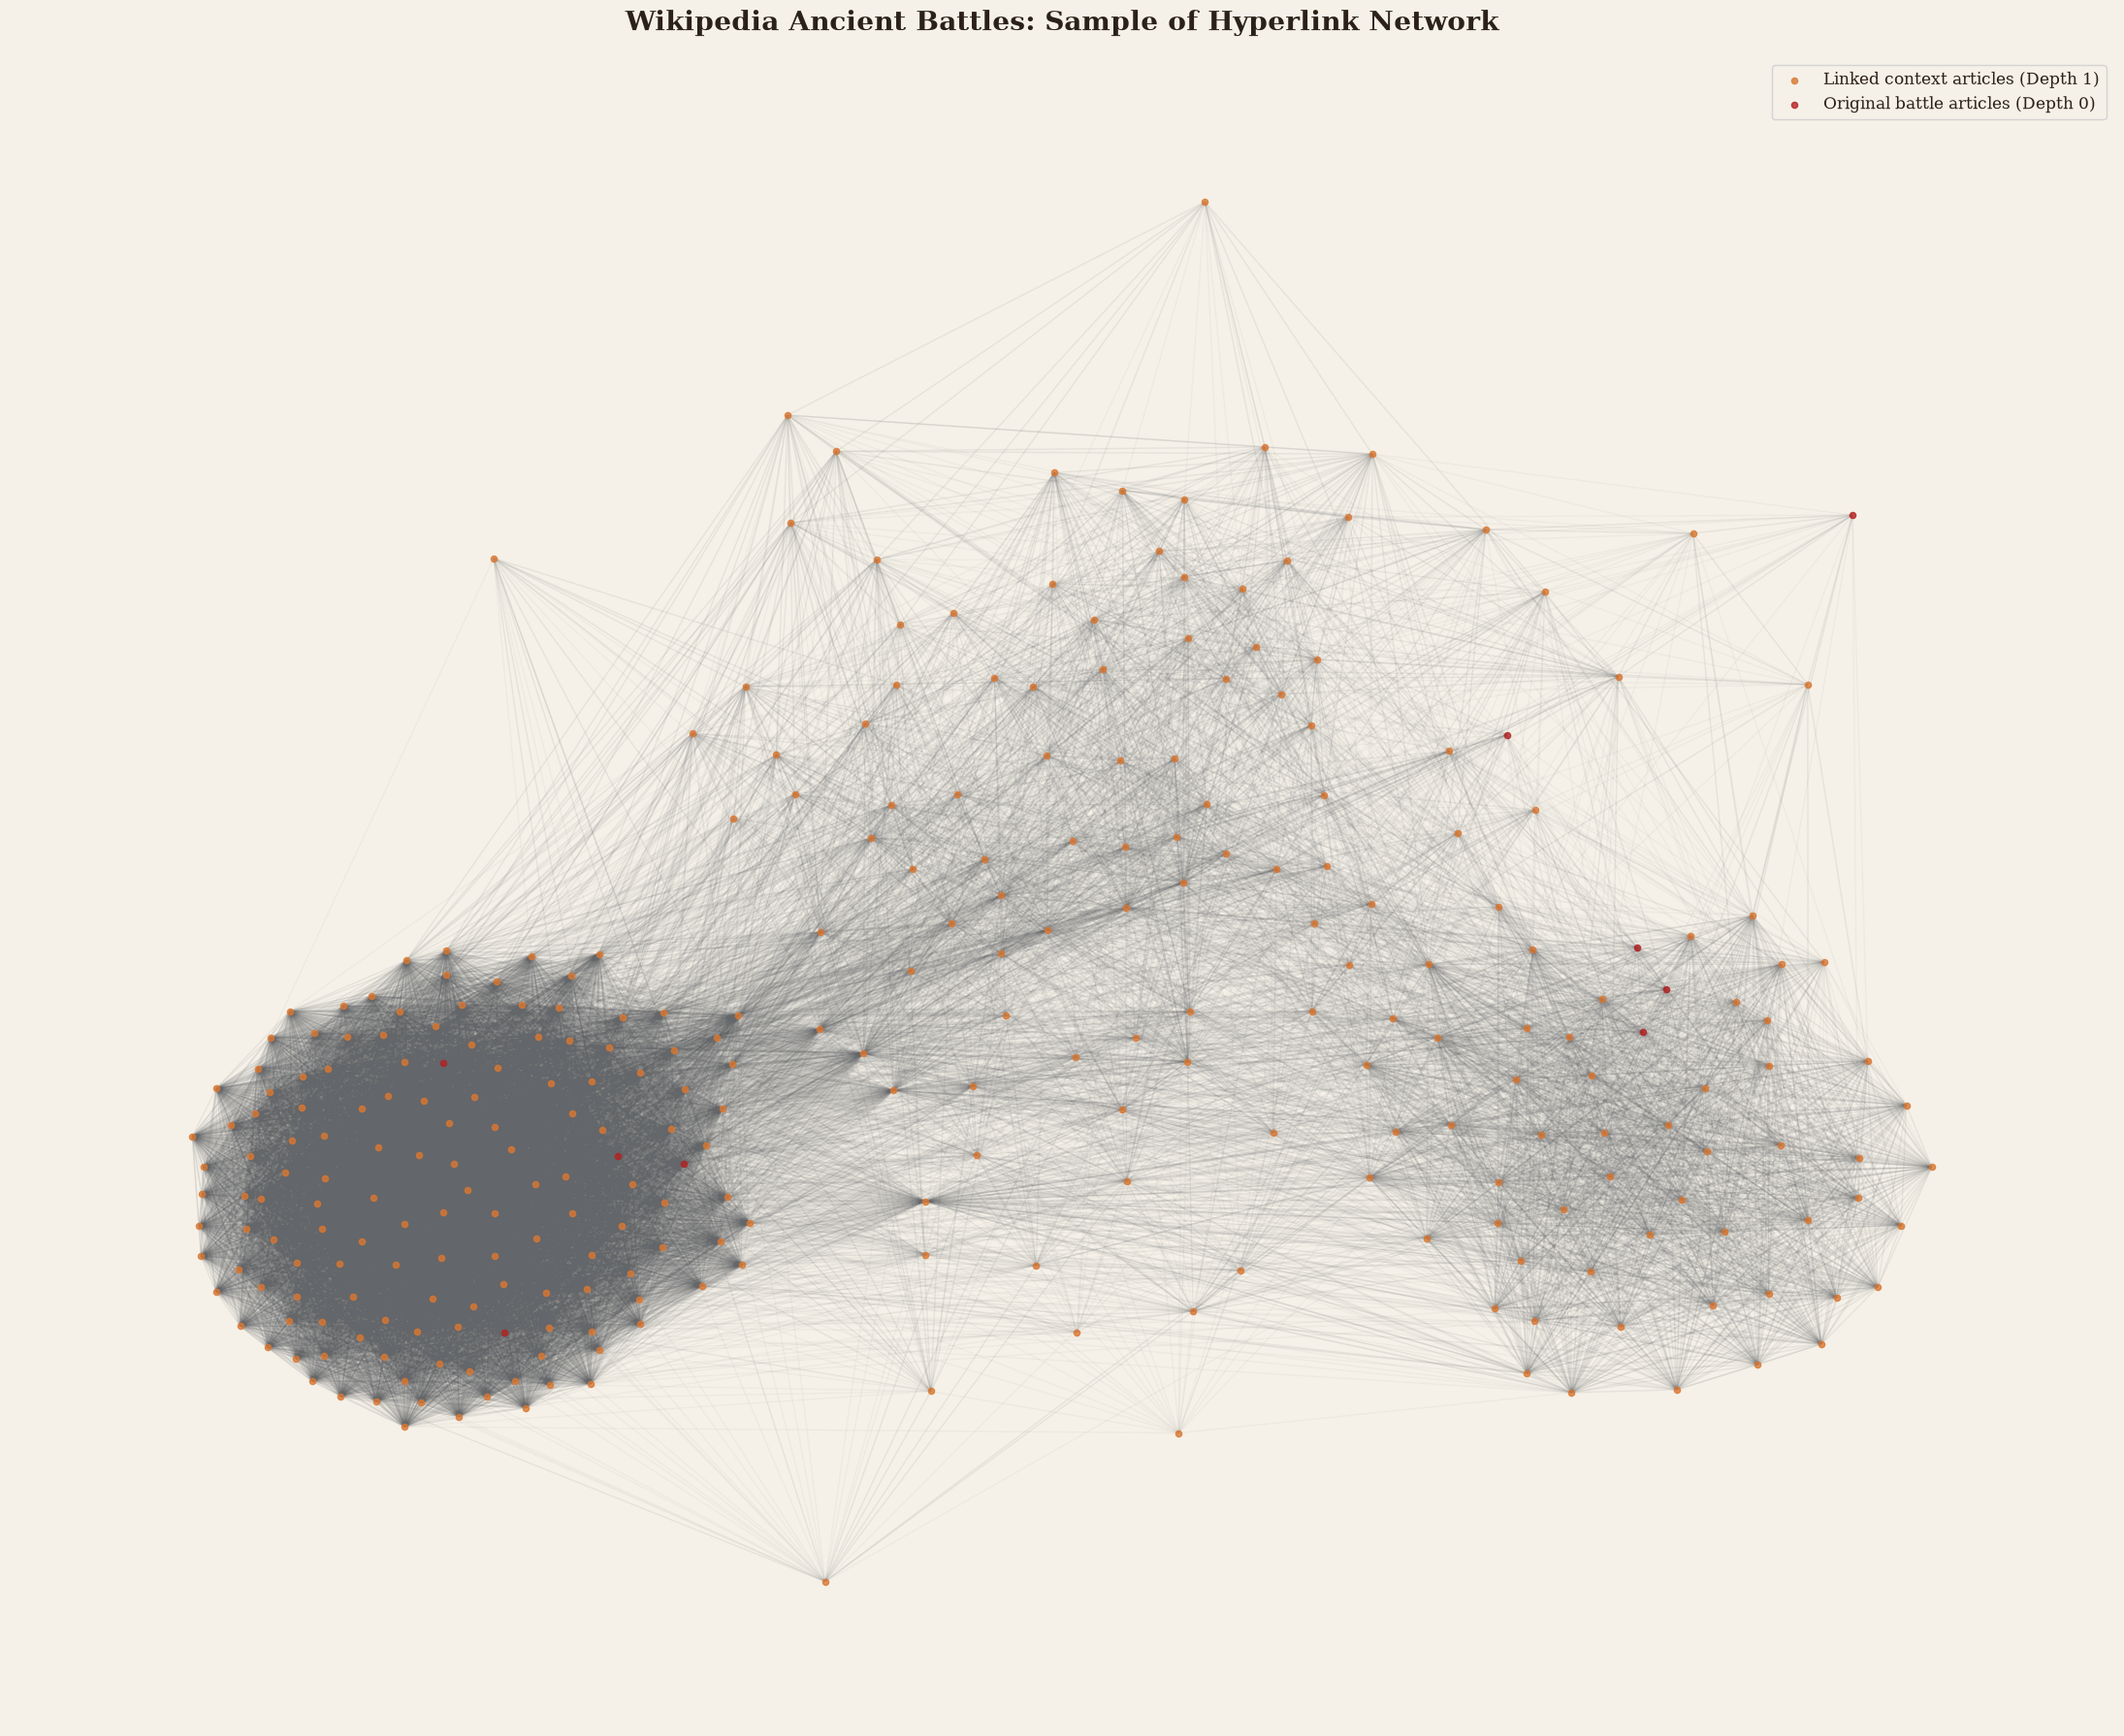

In [98]:
fig, ax = plt.subplots(figsize=(22, 18))

# Calculate network layout
pos = nx.spring_layout(
    G_sample.to_undirected(),
    k=0.12,
    iterations=200,
    seed=6000
)


# Classify nodes directly from the selected Spark results
battle_nodes = (
    top_nodes.loc[top_nodes["crawl_depth"] == 0, "page_id"]
    .astype(int)
    .tolist()
)

context_nodes = (
    top_nodes.loc[top_nodes["crawl_depth"] == 1, "page_id"]
    .astype(int)
    .tolist()
)

print("Original battle articles in visualization:", len(battle_nodes))
print("Context articles in visualization:", len(context_nodes))

# Draw edges first
nx.draw_networkx_edges(
    G_sample,
    pos,
    ax=ax,
    edge_color="#63666A",
    alpha=0.05,
    arrows=False
)

# Draw context articles
nx.draw_networkx_nodes(
    G_sample,
    pos,
    nodelist=context_nodes,
    node_size=20,
    node_color="#D97732",
    alpha=0.80,
    label="Linked context articles (Depth 1)"
)

# Draw original battle articles
nx.draw_networkx_nodes(
    G_sample,
    pos,
    nodelist=battle_nodes,
    node_size=20,
    node_color="#B22222",
    alpha=0.80,
    label="Original battle articles (Depth 0)"
)

# Title and legend
ax.set_title(
    "Wikipedia Ancient Battles: Sample of Hyperlink Network",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.legend(
    loc="upper right",
    fontsize=12,
    frameon=True
)

ax.axis("off")
plt.tight_layout()

# Save visualization
NETWORK_IMAGE_DIR = Path("images/network")
NETWORK_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    NETWORK_IMAGE_DIR / "wikipedia_network_by_depth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## More Vis

### # Network diagnostic output paths

In [99]:


DIAGNOSTICS_DIR = f"{S3_BUCKET}/processed/network/diagnostics"

DEGREE_DISTRIBUTION_DIR = f"{DIAGNOSTICS_DIR}/degree_distributions"
TOP_ARTICLES_DIR = f"{DIAGNOSTICS_DIR}/top_articles"
DEGREE_SCATTER_DIR = f"{DIAGNOSTICS_DIR}/degree_relationship"
EDGE_MIXING_DIR = f"{DIAGNOSTICS_DIR}/edge_mixing"
COMPONENTS_DIR = f"{DIAGNOSTICS_DIR}/connected_components"

# Visualization colors

BATTLE_COLOR = "#B22222"
CONTEXT_COLOR = "#D97732"
NETWORK_COLOR = "#4776A8"

# Local image output folder

NETWORK_IMAGE_DIR = Path("images/network_diagnostics")
NETWORK_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

### Degree distributions

In [100]:
degree_columns = [
    "in_degree",
    "out_degree",
    "total_degree"
]

for degree_column in degree_columns:

    distribution_df = (
        degree_df
        .withColumn(
            "degree_bin",
            F.floor(
                F.log2(F.col(degree_column).cast("double") + 1)
            ).cast("integer")
        )
        .groupBy("degree_bin")
        .agg(
            F.count("*").alias("article_count")
        )
        .orderBy("degree_bin")
    )

    distribution_df.write.mode("overwrite").parquet(
        f"{DEGREE_DISTRIBUTION_DIR}/{degree_column}"
    )

    print(f"Saved {degree_column} distribution.")

Saved in_degree distribution.


Saved out_degree distribution.


Saved total_degree distribution.


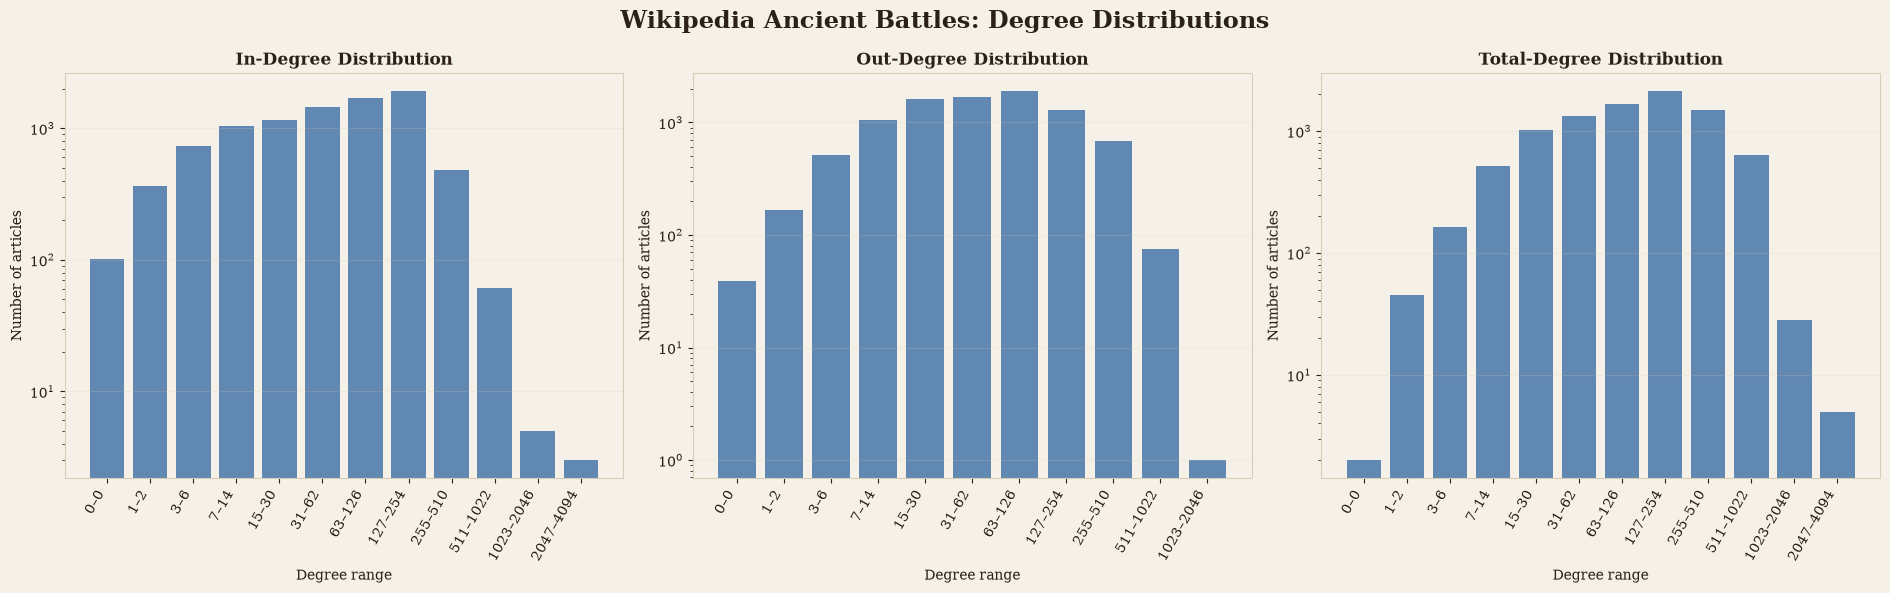

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

degree_titles = [
    ("in_degree", "In-Degree Distribution"),
    ("out_degree", "Out-Degree Distribution"),
    ("total_degree", "Total-Degree Distribution")
]

for ax, (column, title) in zip(axes, degree_titles):

    distribution_df = spark.read.parquet(
        f"{DEGREE_DISTRIBUTION_DIR}/{column}"
    )

    results = distribution_df.orderBy("degree_bin").collect()

    bins = [row["degree_bin"] for row in results]
    counts = [row["article_count"] for row in results]

    labels = [
        f"{2**b - 1}–{2**(b+1) - 2}"
        for b in bins
    ]

    ax.bar(
        range(len(bins)),
        counts,
        color=NETWORK_COLOR,
        alpha=0.85
    )

    ax.set_xticks(range(len(bins)))
    ax.set_xticklabels(labels, rotation=60, ha="right")

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Degree range")
    ax.set_ylabel("Number of articles")
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Wikipedia Ancient Battles: Degree Distributions",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    NETWORK_IMAGE_DIR / "degree_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Top 25 connected articles

In [102]:
# Overall top 25
top_25_overall_df = (
    degree_df
    .orderBy(
        F.desc("total_degree"),
        F.asc("title")
    )
    .limit(25)
)

# Top 25 original battle articles
top_25_battles_df = (
    degree_df
    .filter(F.col("crawl_depth") == 0)
    .orderBy(
        F.desc("total_degree"),
        F.asc("title")
    )
    .limit(25)
)

# Top 25 linked context articles
top_25_context_df = (
    degree_df
    .filter(F.col("crawl_depth") == 1)
    .orderBy(
        F.desc("total_degree"),
        F.asc("title")
    )
    .limit(25)
)

# Save results
top_25_overall_df.write.mode("overwrite").parquet(
    f"{TOP_ARTICLES_DIR}/overall"
)

top_25_battles_df.write.mode("overwrite").parquet(
    f"{TOP_ARTICLES_DIR}/battle_articles"
)

top_25_context_df.write.mode("overwrite").parquet(
    f"{TOP_ARTICLES_DIR}/context_articles"
)

print("Saved all three top-25 rankings.")

Saved all three top-25 rankings.


#### VISUALIZE TOP 25 ARTICLES

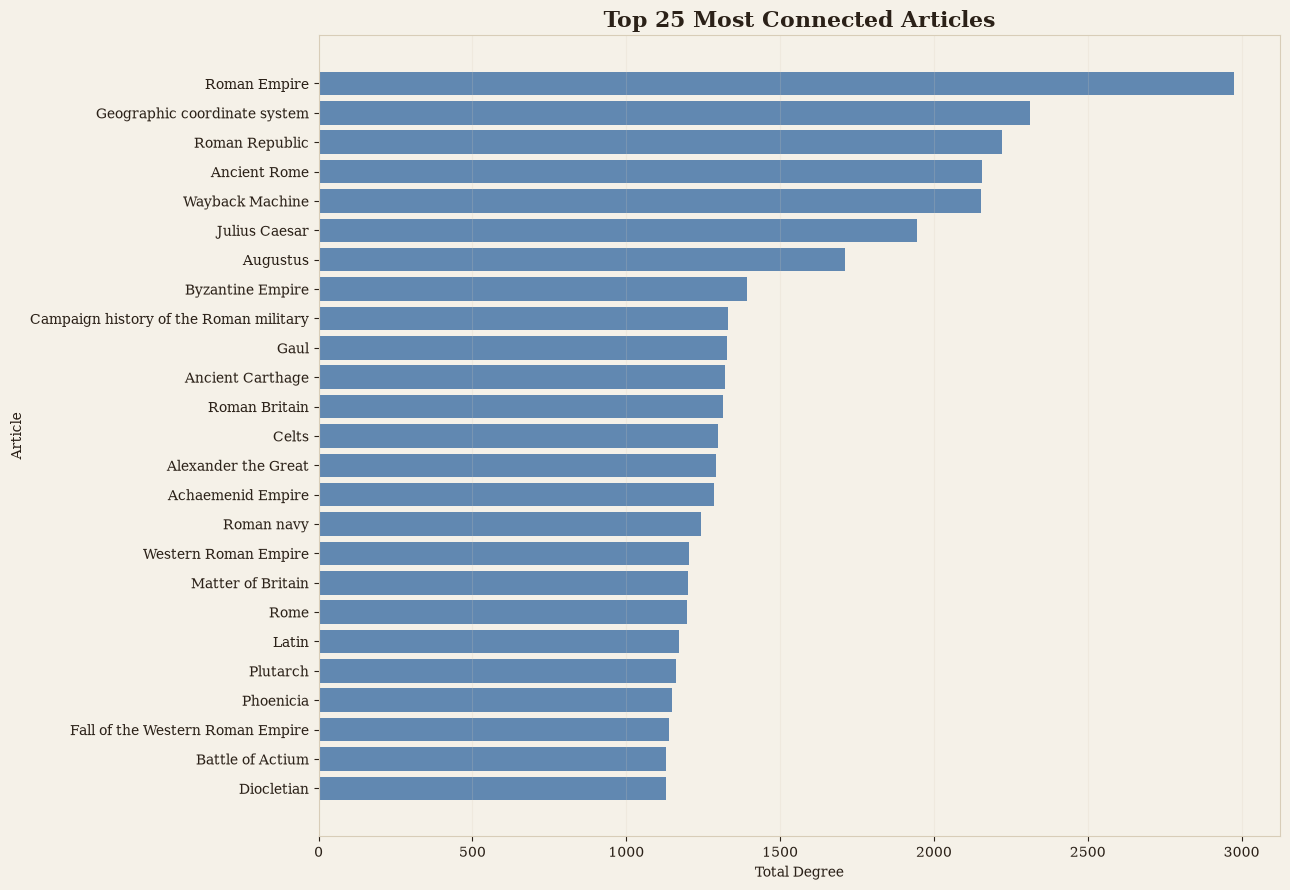

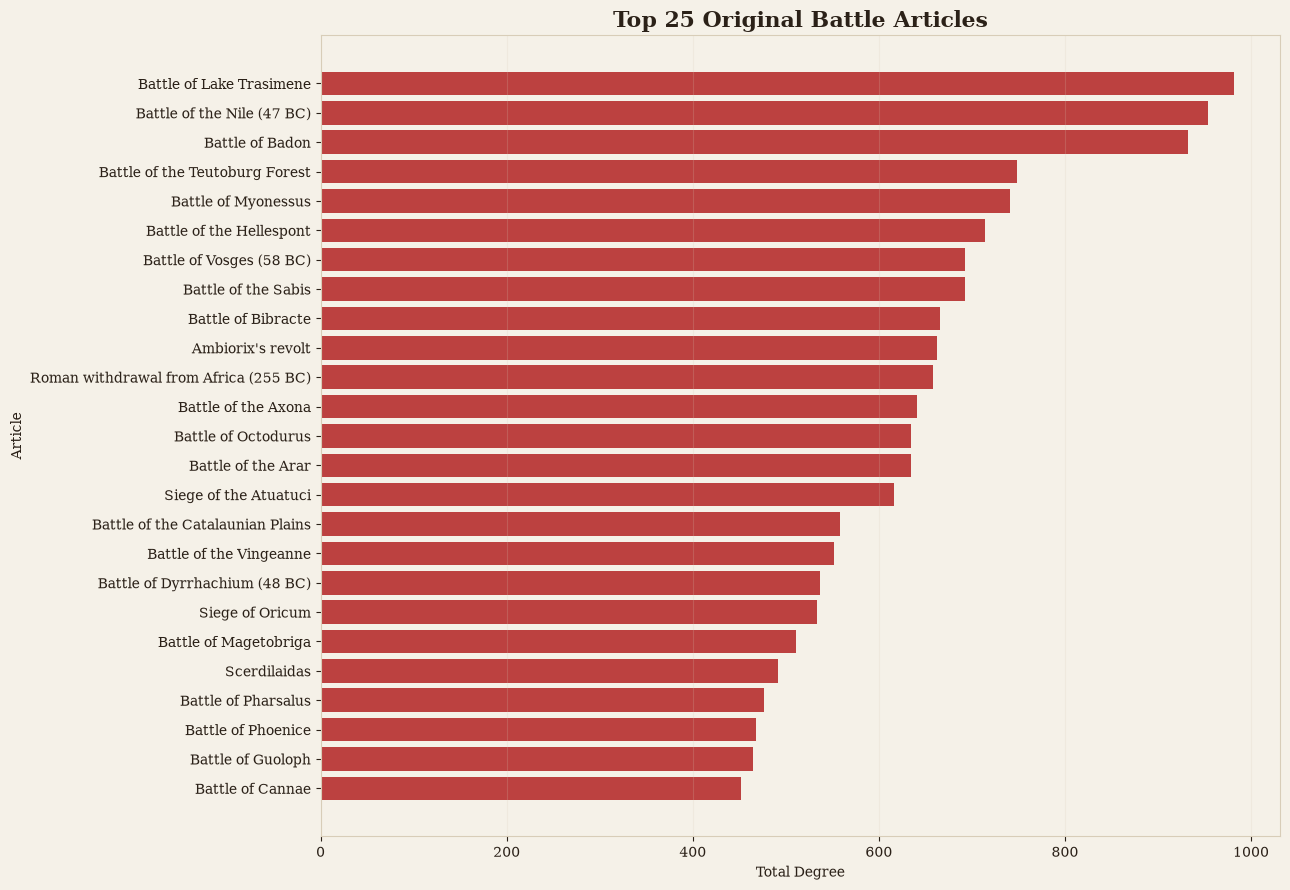

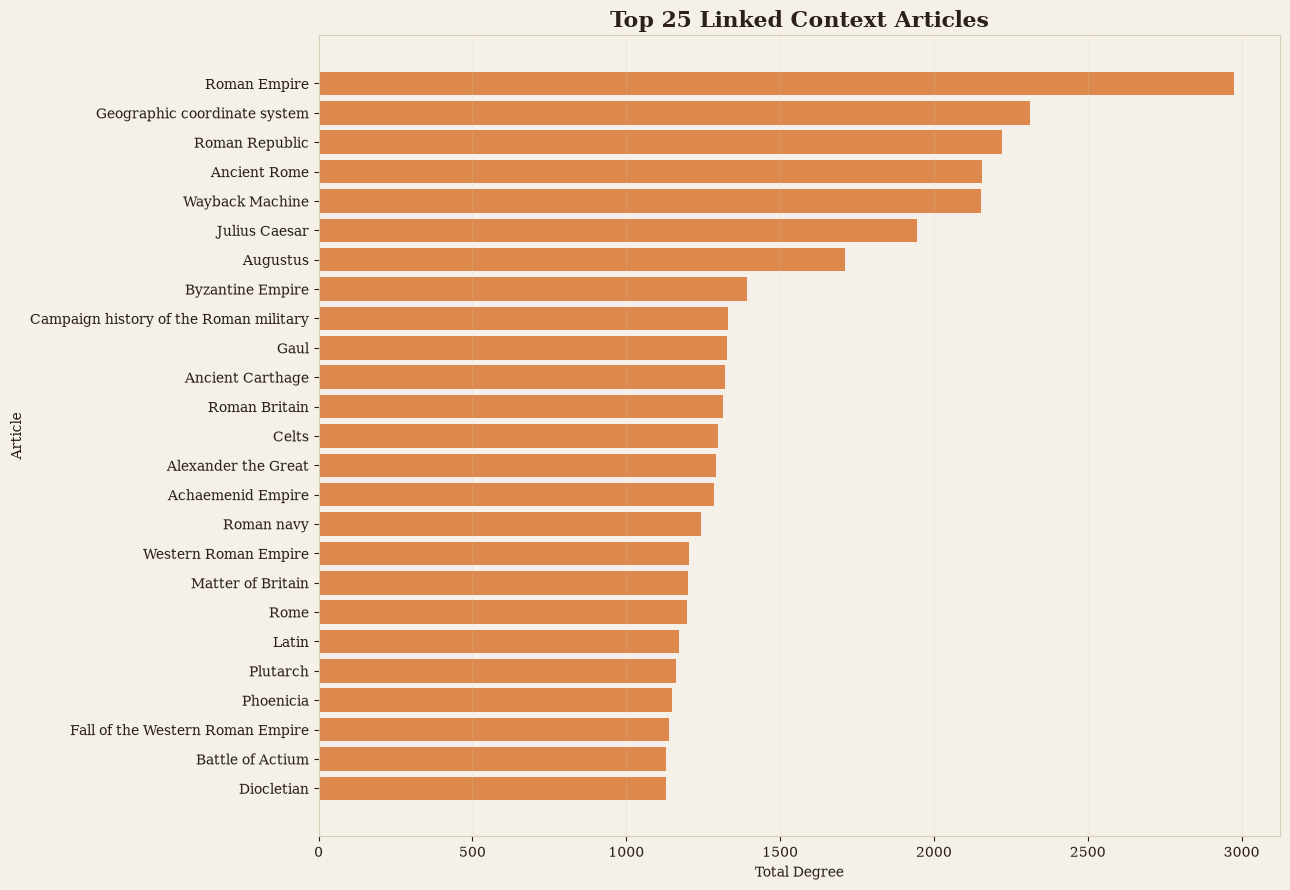

In [103]:


rankings = [
    ("overall", "Top 25 Most Connected Articles"),
    ("battle_articles", "Top 25 Original Battle Articles"),
    ("context_articles", "Top 25 Linked Context Articles")
]

for ranking_name, chart_title in rankings:

    ranking_df = spark.read.parquet(
        f"{TOP_ARTICLES_DIR}/{ranking_name}"
    )

    results = (
        ranking_df
        .orderBy(F.desc("total_degree"), F.asc("title"))
        .collect()
    )

    titles = [row["title"] for row in results]
    degrees = [row["total_degree"] for row in results]

    if ranking_name == "battle_articles":
        color = BATTLE_COLOR
    elif ranking_name == "context_articles":
        color = CONTEXT_COLOR
    else:
        color = NETWORK_COLOR

    fig, ax = plt.subplots(figsize=(13, 9))

    ax.barh(
        titles[::-1],
        degrees[::-1],
        color=color,
        alpha=0.85
    )

    ax.set_title(
        chart_title,
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel("Total Degree")
    ax.set_ylabel("Article")
    ax.grid(axis="x", alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        NETWORK_IMAGE_DIR / f"{ranking_name}_top_25.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### In-degree versus out-degree

In [104]:
degree_relationship_df = (
    degree_df
    .withColumn(
        "in_degree_bin",
        F.floor(
            F.log2(F.col("in_degree").cast("double") + 1)
        ).cast("integer")
    )
    .withColumn(
        "out_degree_bin",
        F.floor(
            F.log2(F.col("out_degree").cast("double") + 1)
        ).cast("integer")
    )
    .groupBy("in_degree_bin", "out_degree_bin")
    .agg(
        F.count("*").alias("article_count")
    )
)

degree_relationship_df.write.mode("overwrite").parquet(
    f"{DEGREE_SCATTER_DIR}/degree_relationship"
)

print("Saved in-degree versus out-degree data.")

Saved in-degree versus out-degree data.


#### Visualize the relationship

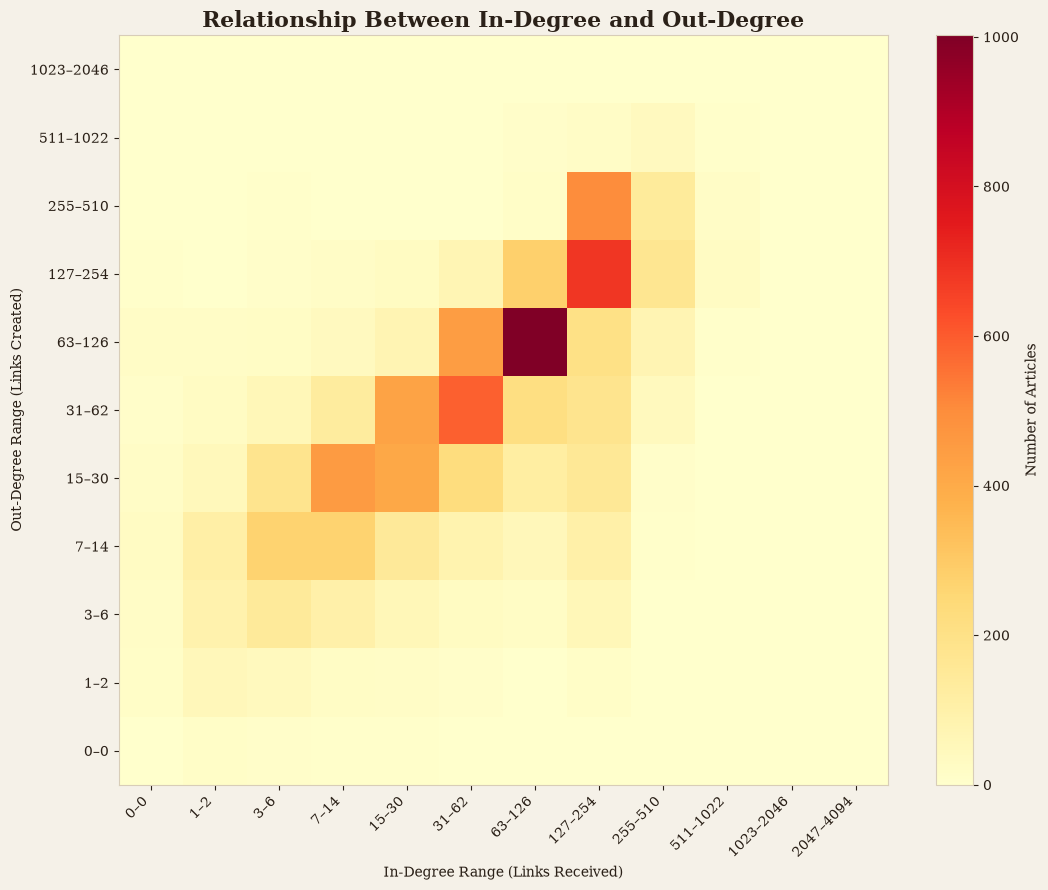

In [105]:


results = (
    degree_relationship_df
    .orderBy("in_degree_bin", "out_degree_bin")
    .collect()
)

in_bins = sorted(set(row["in_degree_bin"] for row in results))
out_bins = sorted(set(row["out_degree_bin"] for row in results))

# Build a small matrix from aggregated Spark results
matrix = [
    [
        next(
            (
                row["article_count"]
                for row in results
                if row["in_degree_bin"] == in_bin
                and row["out_degree_bin"] == out_bin
            ),
            0
        )
        for in_bin in in_bins
    ]
    for out_bin in out_bins
]

fig, ax = plt.subplots(figsize=(11, 9))

heatmap = ax.imshow(
    matrix,
    origin="lower",
    aspect="auto",
    cmap="YlOrRd"
)

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Number of Articles")

ax.set_xticks(range(len(in_bins)))
ax.set_yticks(range(len(out_bins)))

ax.set_xticklabels(
    [f"{2**b - 1}–{2**(b+1) - 2}" for b in in_bins],
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    [f"{2**b - 1}–{2**(b+1) - 2}" for b in out_bins]
)

ax.set_xlabel("In-Degree Range (Links Received)")
ax.set_ylabel("Out-Degree Range (Links Created)")

ax.set_title(
    "Relationship Between In-Degree and Out-Degree",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    NETWORK_IMAGE_DIR / "in_vs_out_degree_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Depth 0 versus Depth 1 edge mixing

In [106]:
source_depth_df = nodes_df.select(
    F.col("page_id").alias("source_page_id"),
    F.col("crawl_depth").alias("source_depth")
)

target_depth_df = nodes_df.select(
    F.col("page_id").alias("target_page_id"),
    F.col("crawl_depth").alias("target_depth")
)

edge_mixing_df = (
    edges_df
    .join(source_depth_df, on="source_page_id", how="inner")
    .join(target_depth_df, on="target_page_id", how="inner")
    .groupBy("source_depth", "target_depth")
    .agg(
        F.count("*").alias("edge_count")
    )
    .orderBy("source_depth", "target_depth")
)

edge_mixing_df.write.mode("overwrite").parquet(
    f"{EDGE_MIXING_DIR}/edge_mixing"
)

display(edge_mixing_df)

DataFrame[source_depth: bigint, target_depth: bigint, edge_count: bigint]

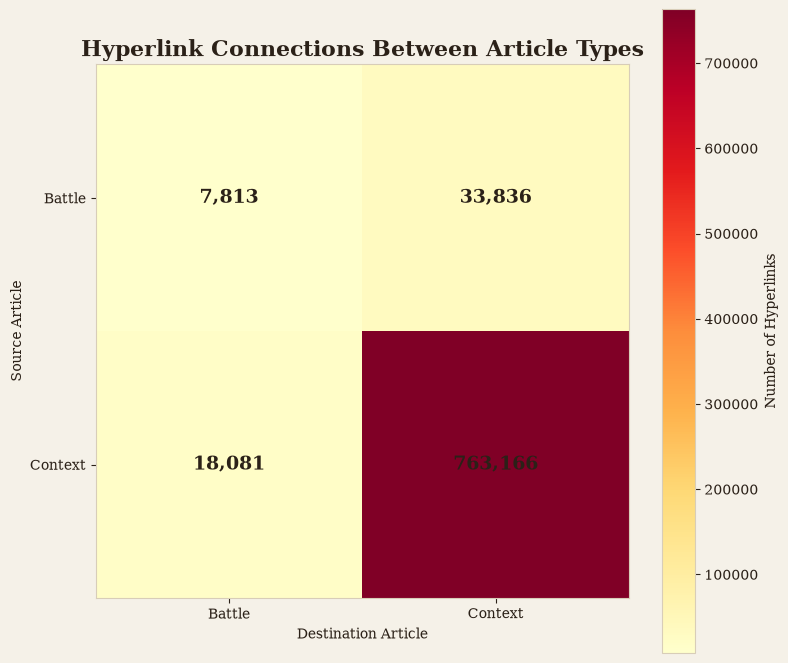

In [107]:
# ============================================
# VISUALIZE EDGE MIXING MATRIX
# ============================================

results = edge_mixing_df.collect()

mixing_matrix = [[0, 0], [0, 0]]

for row in results:
    source = row["source_depth"]
    target = row["target_depth"]

    mixing_matrix[source][target] = row["edge_count"]

fig, ax = plt.subplots(figsize=(8, 7))

heatmap = ax.imshow(
    mixing_matrix,
    cmap="YlOrRd"
)

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Number of Hyperlinks")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Battle", "Context"])
ax.set_yticklabels(["Battle", "Context"])

ax.set_xlabel("Destination Article")
ax.set_ylabel("Source Article")

ax.set_title(
    "Hyperlink Connections Between Article Types",
    fontsize=16,
    fontweight="bold"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{mixing_matrix[i][j]:,}",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold"
        )

plt.tight_layout()

plt.savefig(
    NETWORK_IMAGE_DIR / "edge_mixing_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Connected component sizes

In [108]:
# 1. Create an undirected representation of the edges

forward_edges_df = edges_df.select(
    F.col("source_page_id").alias("src"),
    F.col("target_page_id").alias("dst")
)

reverse_edges_df = edges_df.select(
    F.col("target_page_id").alias("src"),
    F.col("source_page_id").alias("dst")
)

undirected_edges_df = (
    forward_edges_df
    .union(reverse_edges_df)
    .dropDuplicates(["src", "dst"])
    .persist(StorageLevel.MEMORY_AND_DISK)
)

# 2. Initialize every article as its own component

component_labels_df = (
    nodes_df
    .select(
        F.col("page_id"),
        F.col("page_id").alias("component_id")
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)

component_labels_df.count()

# 3. Iteratively propagate the smallest component ID

MAX_ITERATIONS = 500

for iteration in range(MAX_ITERATIONS):

    # Find the current component label of every source article
    neighbor_labels_df = (
        undirected_edges_df.alias("e")
        .join(
            component_labels_df.alias("l"),
            F.col("e.src") == F.col("l.page_id"),
            "inner"
        )
        .select(
            F.col("e.dst").alias("page_id"),
            F.col("l.component_id").alias("neighbor_component")
        )
    )

    # Find the smallest neighboring component label
    minimum_neighbor_df = (
        neighbor_labels_df
        .groupBy("page_id")
        .agg(
            F.min("neighbor_component").alias("minimum_neighbor")
        )
    )

    # Update each article's component label
    updated_labels_df = (
        component_labels_df
        .join(minimum_neighbor_df, on="page_id", how="left")
        .withColumn(
            "component_id",
            F.least(
                F.col("component_id"),
                F.coalesce(
                    F.col("minimum_neighbor"),
                    F.col("component_id")
                )
            )
        )
        .select("page_id", "component_id")
        .localCheckpoint(eager=True)
    )

    # Check whether any component labels changed
    changed_count = (
        component_labels_df.alias("old")
        .join(
            updated_labels_df.alias("new"),
            on="page_id",
            how="inner"
        )
        .filter(
            F.col("old.component_id") != F.col("new.component_id")
        )
        .count()
    )

    # Release the previous iteration's cached labels
    component_labels_df.unpersist()

    component_labels_df = updated_labels_df

    print(
        f"Iteration {iteration + 1}: "
        f"{changed_count} articles changed component"
    )

    # Stop once all labels have stabilized
    if changed_count == 0:
        print("Connected components converged.")
        break

else:
    print(
        "WARNING: Maximum iterations reached. "
        "Component labels may not have fully converged."
    )

# Release the undirected edge cache
undirected_edges_df.unpersist()

NameError: name 'StorageLevel' is not defined